`[1]`

# Avaliação do Maxent por alvo mineral — Irecê

Avalia a eficácia dos modelos de favorabilidade (`maxent_fosfato.py`) com as
amostras exportadas dos **dois mosaicos finais**:

| arquivo (`src/Dados/maxent/`) | mosaico |
|---|---|
| `maxent_amostras_ASTER_mosaico_unico_final_bandas_indices.csv` | mosaico único (etapa 3) |
| `maxent_amostras_aster-mosaico-final_bandas_indices.csv` | mosaico final v1 |

Cada arquivo tem presença (`classe = 1`; 20 pixels no buffer de 500 m de cada
ponto de `pontos_referencia`, todos os alvos) e fundo (`classe = 0`, 10 mil
pixels na grid), com as 36 features do script (bandas, índices,
`phosphorite_rbd`, GLCM da B3N).

**Modelo.** Maxent local como regressão logística com peso infinito no fundo
(IWLR — Fithian & Hastie 2013, *Ann. Appl. Stat.* 7:1917): mesmos termos do
GEE (linear + quadrático, sem produto/hinge/threshold) e regularização L2. É o
mesmo modelo log-linear do Maxent; os valores absolutos de *p* diferem do
`amnhMaxent`, mas a ordenação dos pixels (o que AUC, Boyce e curva de sucesso
medem) é comparável. O mapa final continua saindo do GEE.

**Seções**
1. Dados e exploração dos pontos
2. Separação presença × fundo por feature (antes do modelo)
3. Validação espacial — uma célula de fora por vez: ROC, Boyce, curva de sucesso, omissão
4. Validação independente do fosfato (R2: treina na bacia, testa fora)
5. Modelos nulos
6. Interpretação: importância por permutação, curvas de resposta, redundância
7. Comparação entre alvos e mosaicos; p(outros alvos) como covariável do fosfato
8. Resumo salvo em `models/`

In [ ]:
# [2]
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

RAIZ = Path.cwd().parent if (Path.cwd().parent / 'Dados').exists() else Path.cwd()   # src/
PASTA = RAIZ / 'Dados' / 'maxent'
MODELS = RAIZ / 'modeling' / 'models'
FIGS = MODELS / 'figuras_avaliacao_maxent'
FIGS.mkdir(parents=True, exist_ok=True)

ARQUIVOS = {
    'unico': PASTA / 'maxent_amostras_ASTER_mosaico_unico_final_bandas_indices.csv',
    'v1':    PASTA / 'maxent_amostras_aster-mosaico-final_bandas_indices.csv',
}
ALVOS = ['fosfato', 'carbonato', 'mvt', 'ouro', 'manganes']

# ── parâmetros da análise ───────────────────────────────────────────────────
ALVO    = 'fosfato'     # alvo das seções 2–6
MOSAICO = 'unico'       # mosaico das seções 2–6 ('unico' ou 'v1'); a seção 7 roda os dois
FUNDO   = 'aleatorio'   # 'aleatorio' (como o GEE) ou 'target_group' (presenças dos outros alvos)
C_REG   = 0.1           # inverso da regularização L2 (menor = mais suave; ~ betaMultiplier 2)
PESO_FUNDO = 100        # IWLR: peso de cada pixel de fundo (grande → Maxent)
N_NULO  = 99            # repetições dos modelos nulos
SEED    = 42
rng = np.random.default_rng(SEED)
DPI_FIG = 350           # resolução das figuras salvas

def salvar(fig, celula, nome):
    """Salva a figura em FIGS como c<célula>_<nome>.png a DPI_FIG dpi.
    O prefixo liga o arquivo à célula citada no relatório (docs/relatorio_avaliacao_modelos)."""
    arq = FIGS / f'c{celula}_{nome}.png'
    fig.savefig(arq, dpi=DPI_FIG, bbox_inches='tight')
    print(f'figura → {arq.name}')
    return arq

print(RAIZ)

/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src


`[3]`

## 1. Dados e exploração dos pontos

In [ ]:
# [4]
NAO_FEATURE = {'system:index', '.geo', 'CODIGO_OBJ', 'alvo', 'celula', 'classe', 'features_modo',
               'fonte', 'papel', 'origem', 'swir_estimado', 'camada', 'normalizacao', 'data', 'lon', 'lat'}

def ler(arq):
    df = pd.read_csv(arq)
    xy = df['.geo'].map(lambda g: json.loads(g)['coordinates'])
    df['lon'] = xy.str[0]
    df['lat'] = xy.str[1]
    return df.drop(columns=['system:index', '.geo'])

DADOS = {m: ler(a) for m, a in ARQUIVOS.items()}
FEATURES = sorted(c for c in DADOS['unico'].columns if c not in NAO_FEATURE)
for m, df in DADOS.items():
    n_nan = df[FEATURES].isna().any(axis=1).sum()
    DADOS[m] = df.dropna(subset=FEATURES).reset_index(drop=True)
    print(f'{m}: {len(df)} amostras ({n_nan} com feature vazia, removidas), {len(FEATURES)} features')

df = DADOS[MOSAICO]
pres_pts = df[df.classe == 1].groupby(['alvo', 'CODIGO_OBJ']).agg(
    lon=('lon', 'mean'), lat=('lat', 'mean'), celula=('celula', 'first'),
    papel=('papel', 'first'), fonte=('fonte', 'first'), n=('lon', 'size')).reset_index()
resumo = pres_pts.groupby('alvo').agg(pontos=('CODIGO_OBJ', 'size'), amostras=('n', 'sum'),
                                      celulas=('celula', 'nunique'))
resumo

unico: 31860 amostras (0 com feature vazia, removidas), 36 features
v1: 31860 amostras (0 com feature vazia, removidas), 36 features


,pontos,amostras,celulas
alvo,,,
carbonato,327,6540,23
fosfato,37,740,5
manganes,269,5380,20
mvt,252,5040,20
ouro,208,4160,14


figura → c5a_pontos_todos_v1.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c5a_pontos_todos_v1.png')

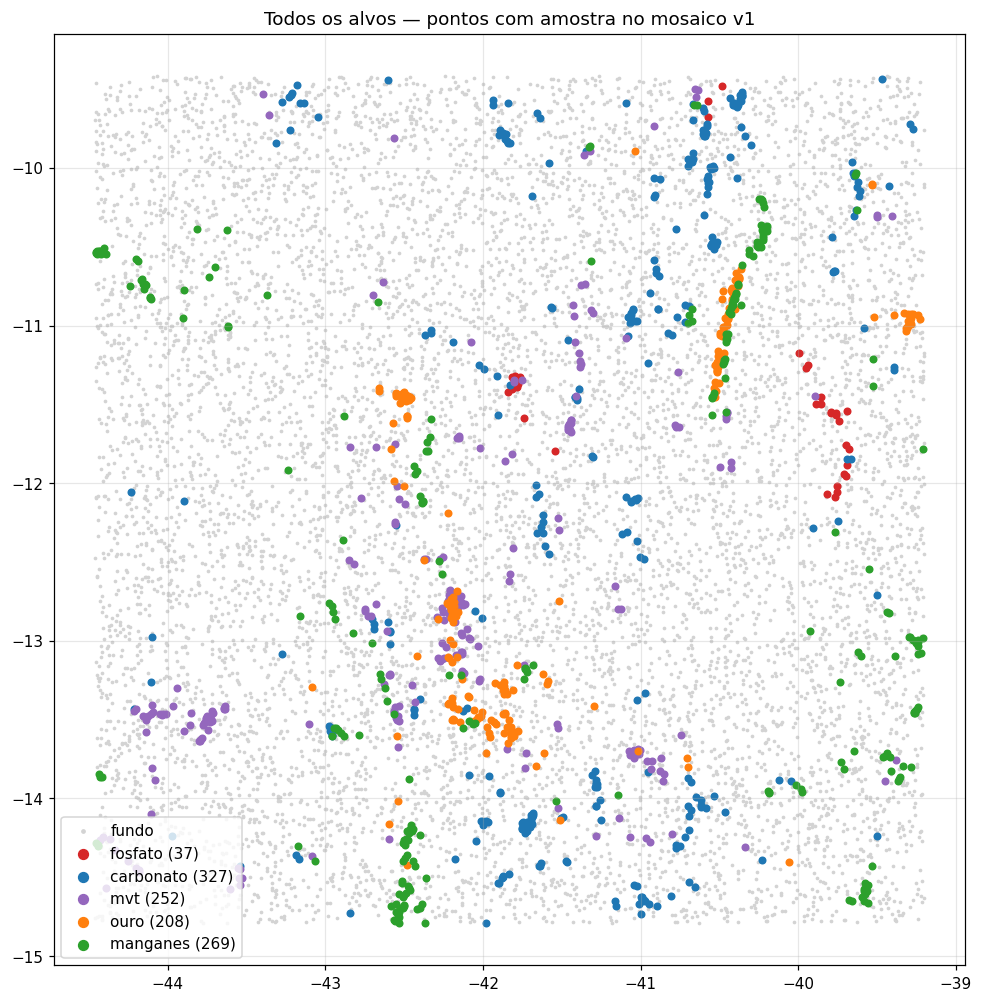

In [ ]:
# [5a]
# Mapas dos pontos com amostra no mosaico MOSAICO_MAPA (v1). Variáveis com sufixo _mapa
# para não trocar o fundo/pres_pts que as outras células usam (MOSAICO).
MOSAICO_MAPA = 'v1'
cores = dict(zip(ALVOS, ['#d62728', '#1f77b4', '#9467bd', '#ff7f0e', '#2ca02c']))
fundo = df[df.classe == 0]

d_mapa = DADOS[MOSAICO_MAPA]
fundo_mapa = d_mapa[d_mapa.classe == 0]
pts_mapa = d_mapa[d_mapa.classe == 1].groupby(['alvo', 'CODIGO_OBJ']).agg(
    lon=('lon', 'mean'), lat=('lat', 'mean'), papel=('papel', 'first'), fonte=('fonte', 'first')).reset_index()

fig, ax = plt.subplots(figsize=(11, 11))
ax.scatter(fundo_mapa.lon, fundo_mapa.lat, s=2, c='lightgrey', label='fundo')
for a in ALVOS:
    p = pts_mapa[pts_mapa.alvo == a]
    ax.scatter(p.lon, p.lat, s=18, c=cores[a], label=f'{a} ({len(p)})')
ax.set_aspect('equal'); ax.legend(fontsize=10, loc='lower left', markerscale=1.5)
ax.set_title(f'Todos os alvos — pontos com amostra no mosaico {MOSAICO_MAPA}')
salvar(fig, '5a', f'pontos_todos_{MOSAICO_MAPA}')

figura → c5b_pontos_fosfato_v1.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c5b_pontos_fosfato_v1.png')

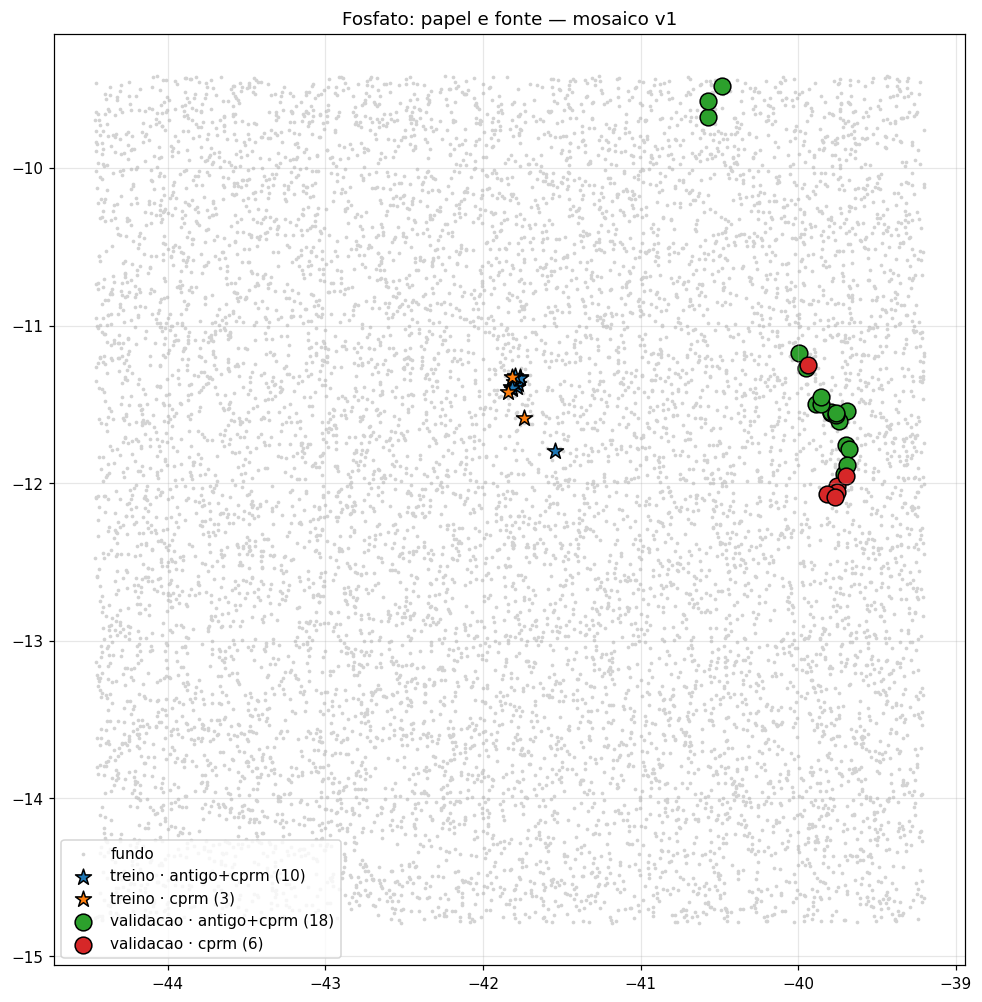

In [ ]:
# [5b]
fig, ax = plt.subplots(figsize=(11, 11))
ax.scatter(fundo_mapa.lon, fundo_mapa.lat, s=2, c='lightgrey', label='fundo')
p = pts_mapa[pts_mapa.alvo == 'fosfato']
for (papel, fonte), g in p.groupby(['papel', 'fonte']):
    ax.scatter(g.lon, g.lat, s=120, marker='*' if papel == 'treino' else 'o',
               edgecolor='k', label=f'{papel} · {fonte} ({len(g)})')
ax.set_aspect('equal'); ax.legend(fontsize=10, loc='lower left')
ax.set_title(f'Fosfato: papel e fonte — mosaico {MOSAICO_MAPA}')
salvar(fig, '5b', f'pontos_fosfato_{MOSAICO_MAPA}')

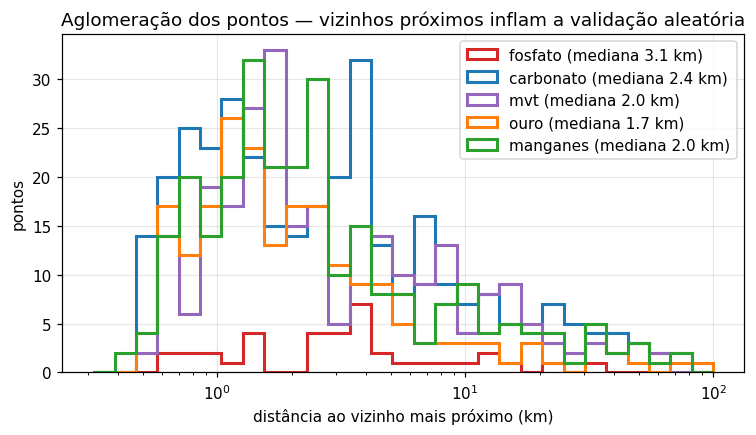

In [ ]:
# [6]
# aglomeração: distância ao vizinho mais próximo do mesmo alvo (km)
def vizinho_km(p):
    xy = np.c_[p.lon * 111 * np.cos(np.radians(p.lat.mean())), p.lat * 111]
    d = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1))
    np.fill_diagonal(d, np.inf)
    return d.min(1)

fig, ax = plt.subplots(figsize=(8, 4))
for a in ALVOS:
    d = vizinho_km(pres_pts[pres_pts.alvo == a])
    ax.hist(d, bins=np.logspace(-0.5, 2, 30), histtype='step', lw=2, color=cores[a],
            label=f'{a} (mediana {np.median(d):.1f} km)')
ax.set_xscale('log'); ax.set_xlabel('distância ao vizinho mais próximo (km)'); ax.set_ylabel('pontos')
ax.legend(); ax.set_title('Aglomeração dos pontos — vizinhos próximos inflam a validação aleatória')
salvar(fig, '6', 'vizinho_mais_proximo')

figura → c6b_clusters_pontos_unico.png


,alvo,pontos,clusters,em_cluster,isolados,maior_cluster,celulas_por_cluster
0,fosfato,37,7,28,9,11,1.14
1,carbonato,327,58,243,84,24,1.07
2,mvt,252,43,176,76,30,1.07
3,ouro,208,22,174,34,26,1.00
4,manganes,269,45,211,58,17,1.13


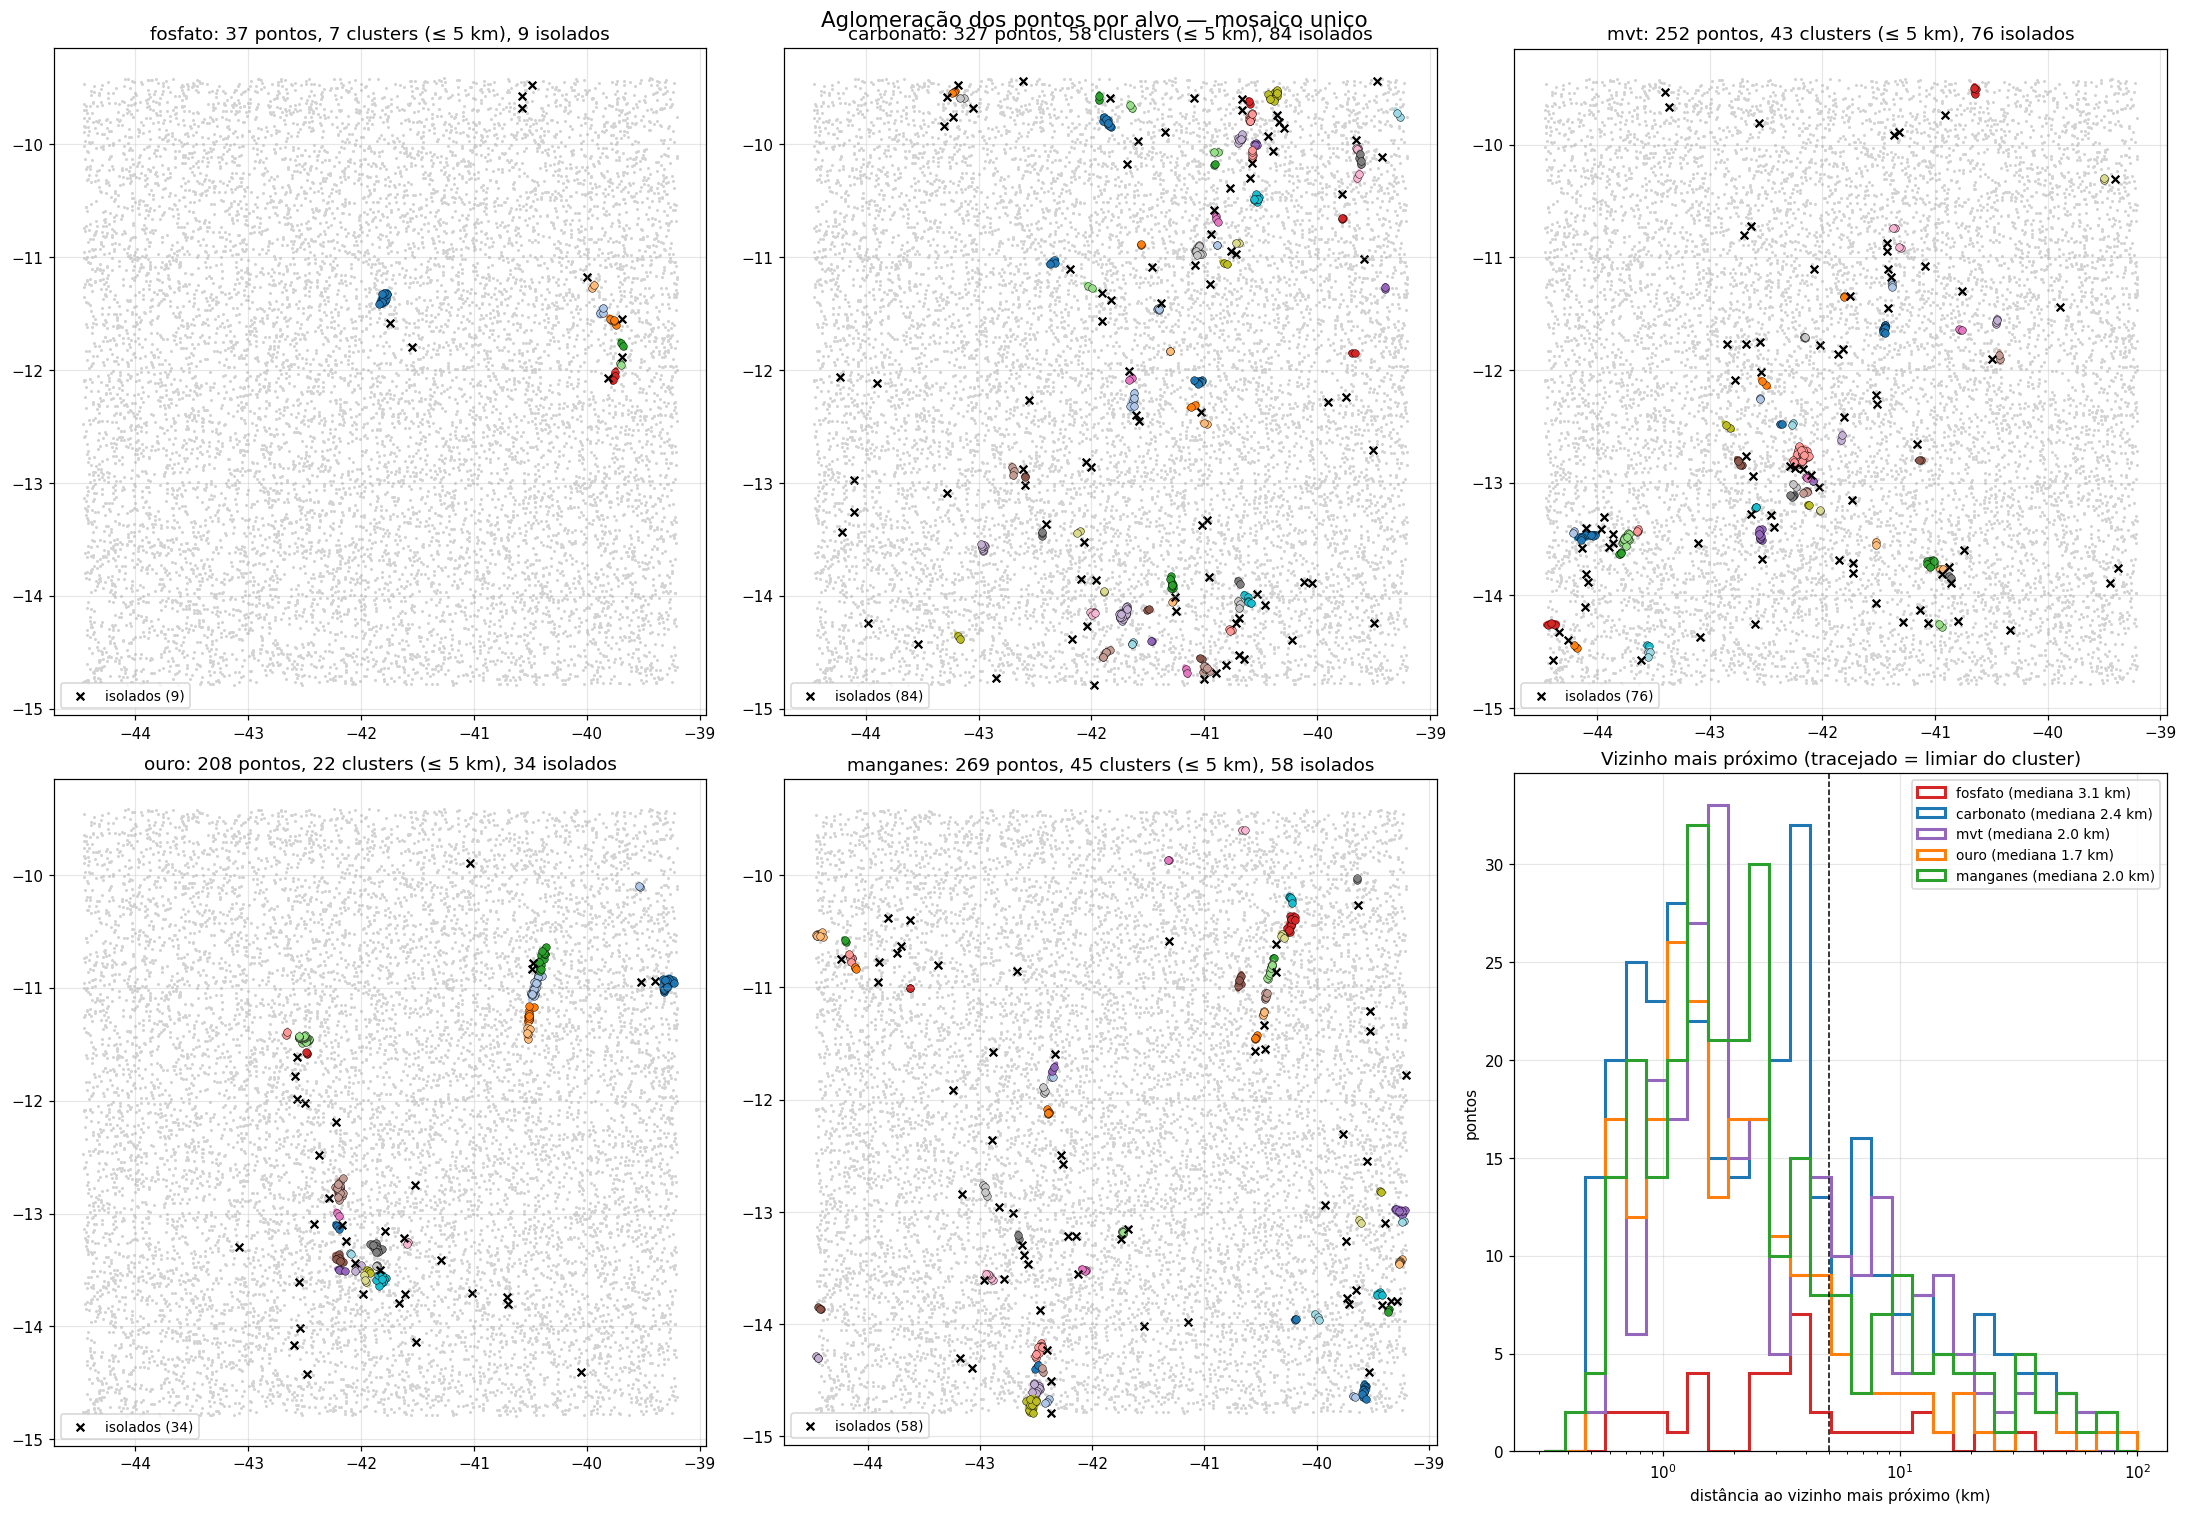

In [ ]:
# [6b]
# Clusters de pontos do mesmo alvo: ligação simples — dois pontos ficam no mesmo
# cluster se houver uma cadeia de vizinhos a ≤ DIST_CLUSTER_KM entre eles
# (DBSCAN com min_samples=1). Elipse = 2 desvios-padrão da posição dos pontos
# do cluster (+ ELIPSE_MIN_KM para clusters de 2 pontos não virarem uma reta).
from matplotlib.patches import Polygon
from sklearn.cluster import DBSCAN

DIST_CLUSTER_KM = 5
ELIPSE_MIN_KM = 1.0
LAT0 = pres_pts.lat.mean()
KX, KY = 111 * np.cos(np.radians(LAT0)), 111      # graus → km

def clusters(p):
    xy = np.c_[p.lon * KX, p.lat * KY]
    return DBSCAN(eps=DIST_CLUSTER_KM, min_samples=1).fit_predict(xy)

def elipse(lon, lat, n_sigma=2):
    xy = np.c_[lon * KX, lat * KY]
    cov = np.cov(xy.T) + np.eye(2) * ELIPSE_MIN_KM ** 2
    val, vec = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, 100)
    borda = (vec @ (n_sigma * np.sqrt(val)[:, None] * np.vstack([np.cos(t), np.sin(t)]))).T + xy.mean(0)
    return np.c_[borda[:, 0] / KX, borda[:, 1] / KY]

resumo_cl = []
fig, axs = plt.subplots(2, 3, figsize=(20, 14))
for ax, a in zip(axs.flat, ALVOS):
    p = pres_pts[pres_pts.alvo == a].copy()
    p['cluster'] = clusters(p)
    tam = p.cluster.map(p.cluster.value_counts())
    ax.scatter(fundo.lon, fundo.lat, s=1, c='lightgrey')
    agrup = p[tam > 1]
    cmap = plt.get_cmap('tab20')
    for k, (cl, g) in enumerate(agrup.groupby('cluster')):
        cor = cmap(k % 20)
        ax.add_patch(Polygon(elipse(g.lon.values, g.lat.values), closed=True,
                             fc=(*cor[:3], 0.15), ec=cor, lw=1.5))
        ax.scatter(g.lon, g.lat, s=25, color=cor, edgecolor='k', lw=0.3)
    iso = p[tam == 1]
    ax.scatter(iso.lon, iso.lat, s=25, marker='x', c='k', label=f'isolados ({len(iso)})')
    n_cl = agrup.cluster.nunique()
    ax.set_title(f'{a}: {len(p)} pontos, {n_cl} clusters (≤ {DIST_CLUSTER_KM} km), {len(iso)} isolados')
    ax.set_aspect('equal'); ax.legend(loc='lower left', fontsize=9)
    resumo_cl.append({'alvo': a, 'pontos': len(p), 'clusters': n_cl, 'em_cluster': len(agrup),
                      'isolados': len(iso), 'maior_cluster': int(tam.max()),
                      'celulas_por_cluster': agrup.groupby('cluster').celula.nunique().mean()})

# último painel: histograma da distância ao vizinho mais próximo
ax = axs.flat[-1]
for a in ALVOS:
    d = vizinho_km(pres_pts[pres_pts.alvo == a])
    ax.hist(d, bins=np.logspace(-0.5, 2, 30), histtype='step', lw=2, color=cores[a],
            label=f'{a} (mediana {np.median(d):.1f} km)')
ax.axvline(DIST_CLUSTER_KM, c='k', ls='--', lw=1)
ax.set_xscale('log'); ax.set_xlabel('distância ao vizinho mais próximo (km)'); ax.set_ylabel('pontos')
ax.legend(fontsize=9); ax.set_title('Vizinho mais próximo (tracejado = limiar do cluster)')

fig.suptitle(f'Aglomeração dos pontos por alvo — mosaico {MOSAICO}', fontsize=14)
fig.tight_layout()
salvar(fig, '6b', f'clusters_pontos_{MOSAICO}')
pd.DataFrame(resumo_cl).round(2)


`[7]`

## 2. Separação presença × fundo por feature

Antes de qualquer modelo: quanto cada feature, **sozinha**, separa as amostras
do alvo das amostras de fundo. Duas medidas, calculadas na célula 8.

### *d* de Cohen

Mede a distância entre as médias dos dois grupos **em unidades de desvio-padrão**:

$$
d = \frac{\bar{x}_{\text{presença}} - \bar{x}_{\text{fundo}}}{s},
\qquad
s = \sqrt{\frac{s^2_{\text{presença}} + s^2_{\text{fundo}}}{2}}
$$

- $\bar{x}$ = média da feature em cada grupo; $s$ = desvio-padrão médio dos
  dois grupos (o "tamanho típico" da variação daquela feature).
- Dividir por $s$ deixa features de escalas diferentes comparáveis: uma banda
  em reflectância × 1000 (centenas) e uma razão como `carbonate_8_6` (≈ 0,6)
  passam a ser medidas na mesma régua.
- **Sinal:** $d > 0$ (barra vermelha no gráfico) = a feature é **maior** nas
  ocorrências que na paisagem; $d < 0$ (azul) = **menor**. O sinal diz a
  direção; o tamanho diz a força.
- **Leitura usual** (Cohen 1988), em valor absoluto:

  | \|d\| | efeito | sobreposição aproximada das duas distribuições |
  |---|---|---|
  | 0,2 | pequeno | ~85 % |
  | 0,5 | médio | ~67 % |
  | 0,8 | grande | ~53 % |
  | 1,2+ | muito grande | < 45 % |

- Exemplo: `B07` com $d = 0{,}9$ quer dizer que a média da B07 nos pontos de
  fosfato está 0,9 desvio-padrão acima da média do fundo — as curvas da
  célula 9 aparecem deslocadas, mas ainda se cruzam bastante.

**Limites do *d*:** supõe distribuições parecidas com a normal e só olha a
média. Uma feature em que o alvo ocupa uma **faixa estreita no meio** da
paisagem (nem alto nem baixo) dá $d \approx 0$ mesmo separando bem — o
Maxent pega isso com o termo quadrático. Por isso o *d* vem junto com a AUC.

### AUC univariada

Probabilidade de um pixel de presença sorteado ter valor maior que um pixel de
fundo sorteado, usando só essa feature. 0,5 = não separa; 1 = separa
totalmente (presença sempre maior); 0 = separa totalmente no sentido oposto.
A coluna `forca` = |AUC − 0,5| ordena as features pela força, independente do
sentido. Não depende de normalidade, mas também não vê a "faixa do meio".

**Cuidado:** as duas medidas usam todas as amostras juntas, sem separar
células. Uma feature pode separar bem só porque os pontos estão concentrados
em poucas células com uma cena ou um solo particular — a seção 3 (célula de
fora) é que diz se a separação se repete em outro lugar.

figura → c8_separacao_fosfato_unico.png


,feature,cohen_d,auc_uni,forca
28,kaolinite_7_5,0.878,0.752,0.252
5,B07,0.940,0.750,0.250
0,B01,0.670,0.738,0.238
3,B05,0.863,0.730,0.230
4,B06,0.863,0.729,0.229
6,B08,0.848,0.729,0.229
35,sultan_r,-0.772,0.271,0.229
29,muscovite_7_6,0.722,0.726,0.226
1,B02,0.774,0.726,0.226
2,B04,0.831,0.719,0.219


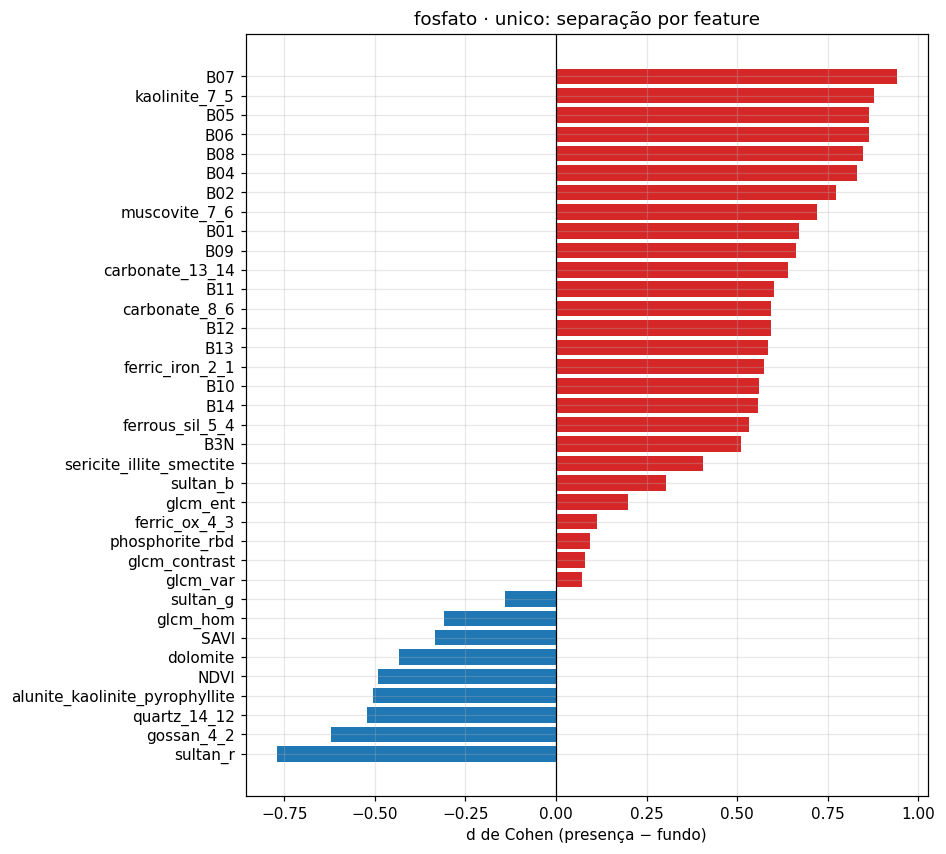

In [ ]:
# [8]
def separacao(df, alvo):
    p = df[(df.classe == 1) & (df.alvo == alvo)]
    f = df[df.classe == 0]
    linhas = []
    for c in FEATURES:
        sd = np.sqrt((p[c].var() + f[c].var()) / 2)
        y = np.r_[np.ones(len(p)), np.zeros(len(f))]
        linhas.append({'feature': c, 'cohen_d': (p[c].mean() - f[c].mean()) / sd,
                       'auc_uni': roc_auc_score(y, np.r_[p[c], f[c]])})
    return pd.DataFrame(linhas).assign(forca=lambda t: (t.auc_uni - 0.5).abs()).sort_values('forca', ascending=False)

sep = separacao(df, ALVO)
fig, ax = plt.subplots(figsize=(8, 9))
s = sep.sort_values('cohen_d')
ax.barh(s.feature, s.cohen_d, color=np.where(s.cohen_d > 0, '#d62728', '#1f77b4'))
ax.axvline(0, c='k', lw=0.8)
ax.set_xlabel("d de Cohen (presença − fundo)"); ax.set_title(f'{ALVO} · {MOSAICO}: separação por feature')
salvar(fig, '8', f'separacao_{ALVO}_{MOSAICO}')
sep.head(10).round(3)

figura → c9_distribuicoes_top8_fosfato_unico.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c9_distribuicoes_top8_fosfato_unico.png')

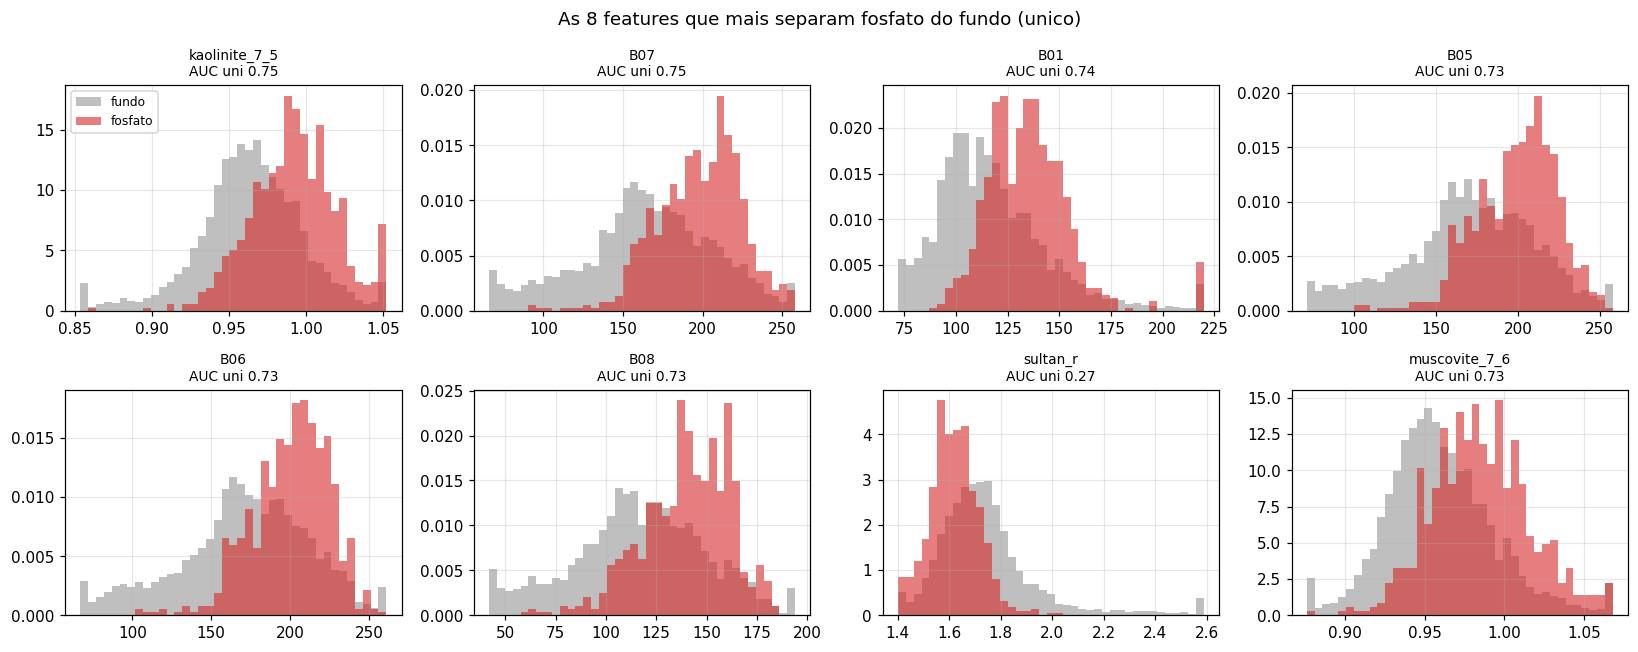

In [ ]:
# [9]
top = sep.feature.head(8).tolist()
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
p = df[(df.classe == 1) & (df.alvo == ALVO)]
f = df[df.classe == 0]
for ax, c in zip(axs.flat, top):
    lo, hi = np.nanpercentile(f[c], [1, 99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(f[c].clip(lo, hi), bins=bins, density=True, alpha=0.5, color='grey', label='fundo')
    ax.hist(p[c].clip(lo, hi), bins=bins, density=True, alpha=0.6, color=cores[ALVO], label=ALVO)
    ax.set_title(f'{c}\nAUC uni {sep.set_index("feature").auc_uni[c]:.2f}', fontsize=9)
axs.flat[0].legend(fontsize=8)
fig.suptitle(f'As 8 features que mais separam {ALVO} do fundo ({MOSAICO})')
fig.tight_layout()
salvar(fig, '9', f'distribuicoes_top8_{ALVO}_{MOSAICO}')

`[10]`

## 3. Modelo e validação espacial (uma célula de fora por vez)

Para cada célula da grid: treina sem as amostras (presença e fundo) da célula
e prediz as amostras dela. Juntando todas as células, cada amostra recebe uma
predição **fora da amostra** (OOF). Pontos de uma mesma célula saem juntos —
evita AUC inflada por vizinhos (seção 1).

Métricas:
- **AUC** presença × fundo (por amostra e por ponto — mediana dos 20 pixels).
- **Índice de Boyce contínuo** (Hirzel et al. 2006): correlação de Spearman
  entre a classe de *p* e a razão observado/esperado (P/E). Vai de −1 a 1;
  > 0,5 é bom, perto de 0 = aleatório, negativo = modelo invertido.
- **Curva de sucesso**: % da área (fundo) acima do limiar × % das ocorrências
  capturadas. A área sob ela e o "% de pontos nos 10 % mais favoráveis" são a
  leitura prática para campo.
- **Omissão por limiar** (mínimo das presenças, percentil 10).

In [ ]:
# [11]
def termos(X):
    return np.hstack([X, X ** 2])          # linear + quadrático (sem produto), como no GEE

class MaxentIWLR:
    def __init__(self, C=C_REG, peso_fundo=PESO_FUNDO):
        self.C, self.peso = C, peso_fundo
    def fit(self, Xp, Xf):
        self.sc = StandardScaler().fit(Xf)        # escala da paisagem
        X = termos(np.clip(self.sc.transform(np.r_[Xp, Xf]), -6, 6))
        y = np.r_[np.ones(len(Xp)), np.zeros(len(Xf))]
        # addSamplesToBackground: presença também entra no fundo
        X = np.r_[X, X[:len(Xp)]]
        y = np.r_[y, np.zeros(len(Xp))]
        w = np.where(y == 1, 1.0, self.peso)
        w = w * len(y) / w.sum()
        self.lr = LogisticRegression(C=self.C, max_iter=2000).fit(X, y, sample_weight=w)
        return self
    def predict(self, X):
        z = self.lr.decision_function(termos(np.clip(self.sc.transform(X), -6, 6)))
        return 1 / (1 + np.exp(-z))

def conjunto(df, alvo, fundo=FUNDO, papeis=None):
    p = df[(df.classe == 1) & (df.alvo == alvo)]
    if papeis:
        p = p[p.papel.isin(papeis)]
    if fundo == 'target_group':
        f = df[(df.classe == 1) & (df.alvo != alvo)].assign(classe=0)
    else:
        f = df[df.classe == 0]
    return p, f

def oof_por_celula(p, f, feats=FEATURES, Modelo=None):
    """Predição fora da amostra: treina sem a célula c, prediz as amostras de c.
    Modelo = classe com fit(Xp, Xf) / predict(X); padrão MaxentIWLR."""
    Modelo = Modelo or MaxentIWLR
    op, of = pd.Series(np.nan, index=p.index), pd.Series(np.nan, index=f.index)
    for c in sorted(set(p.celula) | set(f.celula)):
        tp, tf = p[p.celula != c], f[f.celula != c]
        m = Modelo().fit(tp[feats].values, tf[feats].values)
        if (p.celula == c).any():
            op[p.celula == c] = m.predict(p.loc[p.celula == c, feats].values)
        if (f.celula == c).any():
            of[f.celula == c] = m.predict(f.loc[f.celula == c, feats].values)
    return op, of

def boyce(pp, pf, n_janelas=91, largura=0.1):
    """Índice de Boyce contínuo com janelas de área igual: cada janela cobre
    `largura` do fundo (E = largura); P = fração das presenças na janela.
    Eixo = percentil de p no fundo (0 = área menos favorável, 1 = mais).
    Janelas em escala de p ficam quase vazias nos extremos e distorcem o índice."""
    from scipy.stats import spearmanr
    u = np.searchsorted(np.sort(pf), pp) / len(pf)       # percentil de cada presença no fundo
    cent = np.linspace(largura / 2, 1 - largura / 2, n_janelas)
    pe = np.array([((u >= c - largura / 2) & (u < c + largura / 2)).mean() / largura for c in cent])
    return spearmanr(cent, pe).statistic, cent, pe

def sucesso(pp, pf):
    """% da área (fundo) acima de cada limiar × % das presenças capturadas."""
    lim = np.unique(np.r_[pp, np.quantile(pf, np.linspace(0, 1, 201))])[::-1]
    area = np.array([(pf >= t).mean() for t in lim])
    capt = np.array([(pp >= t).mean() for t in lim])
    return area, capt

def metricas(op, of, p):
    pp, pf = op.values, of.values
    y = np.r_[np.ones(len(pp)), np.zeros(len(pf))]
    por_ponto = op.groupby(p.CODIGO_OBJ).median().values
    area, capt = sucesso(por_ponto, pf)
    b, _, _ = boyce(pp, pf)
    return {'auc_amostra': roc_auc_score(y, np.r_[pp, pf]),
            'auc_ponto': roc_auc_score(np.r_[np.ones(len(por_ponto)), np.zeros(len(pf))], np.r_[por_ponto, pf]),
            'boyce': b,
            'pontos_top10pct_area': np.interp(0.10, area, capt),
            'pontos_top25pct_area': np.interp(0.25, area, capt),
            'auc_sucesso': np.trapezoid(capt, area),
            'n_pontos': len(por_ponto), 'n_celulas': p.celula.nunique()}

In [ ]:
# [12]
p, f = conjunto(df, ALVO)
op, of = oof_por_celula(p, f)
M = metricas(op, of, p)
# mesma métrica dentro da amostra: a diferença mede quanto o modelo decora o lugar
m_in = MaxentIWLR().fit(p[FEATURES].values, f[FEATURES].values)
M_in = metricas(pd.Series(m_in.predict(p[FEATURES].values), index=p.index),
                pd.Series(m_in.predict(f[FEATURES].values), index=f.index), p)
pd.DataFrame({'célula de fora (OOF)': M, 'dentro da amostra': M_in}).round(3)

,célula de fora (OOF),dentro da amostra
auc_amostra,0.565,0.835
auc_ponto,0.578,0.866
boyce,0.578,0.991
pontos_top10pct_area,0.027,0.459
pontos_top25pct_area,0.216,0.865
auc_sucesso,0.579,0.867
n_pontos,37.000,37.000
n_celulas,5.000,5.000


figura → c13_validacao_fosfato_unico_aleatorio.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c13_validacao_fosfato_unico_aleatorio.png')

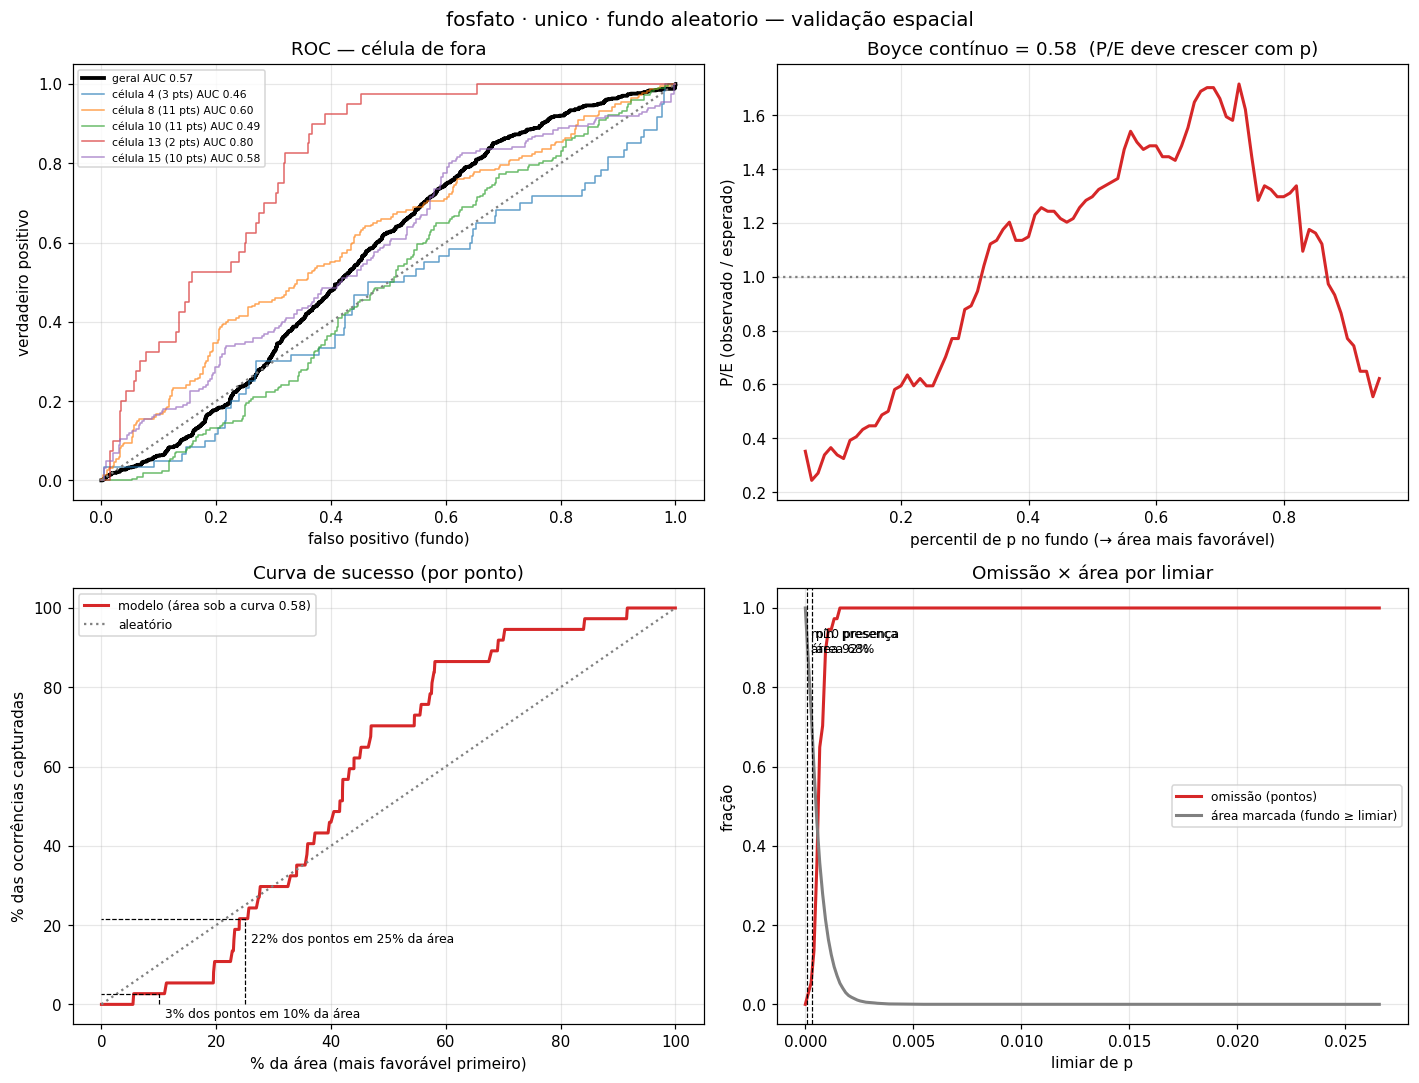

In [ ]:
# [13]
fig, axs = plt.subplots(2, 2, figsize=(13, 10))
y = np.r_[np.ones(len(op)), np.zeros(len(of))]

# ROC geral e por célula deixada de fora
ax = axs[0, 0]
fpr, tpr, _ = roc_curve(y, np.r_[op, of])
ax.plot(fpr, tpr, 'k', lw=2.5, label=f'geral AUC {M["auc_amostra"]:.2f}')
for c in sorted(p.celula.unique()):
    sp, sf = op[p.celula == c], of[f.celula == c]
    if len(sf) == 0:
        continue
    yy = np.r_[np.ones(len(sp)), np.zeros(len(sf))]
    a, b_, _ = roc_curve(yy, np.r_[sp, sf])
    ax.plot(a, b_, lw=1, alpha=0.7, label=f'célula {c} ({p[p.celula == c].CODIGO_OBJ.nunique()} pts) '
                                         f'AUC {roc_auc_score(yy, np.r_[sp, sf]):.2f}')
ax.plot([0, 1], [0, 1], ':', c='grey'); ax.set_xlabel('falso positivo (fundo)'); ax.set_ylabel('verdadeiro positivo')
ax.set_title('ROC — célula de fora'); ax.legend(fontsize=7)

# Boyce
ax = axs[0, 1]
b, cent, pe = boyce(op.values, of.values)
ax.plot(cent, pe, c=cores[ALVO], lw=2); ax.axhline(1, c='grey', ls=':')
ax.set_xlabel('percentil de p no fundo (→ área mais favorável)'); ax.set_ylabel('P/E (observado / esperado)')
ax.set_title(f'Boyce contínuo = {b:.2f}  (P/E deve crescer com p)')

# Curva de sucesso
ax = axs[1, 0]
area, capt = sucesso(op.groupby(p.CODIGO_OBJ).median().values, of.values)
ax.plot(area * 100, capt * 100, c=cores[ALVO], lw=2, label=f'modelo (área sob a curva {M["auc_sucesso"]:.2f})')
ax.plot([0, 100], [0, 100], ':', c='grey', label='aleatório')
for q in (10, 25):
    v = np.interp(q / 100, area, capt) * 100
    ax.plot([q, q, 0], [0, v, v], '--', c='k', lw=0.8)
    ax.text(q + 1, v - 6, f'{v:.0f}% dos pontos em {q}% da área', fontsize=8)
ax.set_xlabel('% da área (mais favorável primeiro)'); ax.set_ylabel('% das ocorrências capturadas')
ax.set_title('Curva de sucesso (por ponto)'); ax.legend(fontsize=8)

# Omissão por limiar
ax = axs[1, 1]
lims = np.linspace(0, of.max(), 200)
ponto = op.groupby(p.CODIGO_OBJ).median()
ax.plot(lims, [(ponto < t).mean() for t in lims], c=cores[ALVO], lw=2, label='omissão (pontos)')
ax.plot(lims, [(of >= t).mean() for t in lims], c='grey', lw=2, label='área marcada (fundo ≥ limiar)')
for nome, t in [('mín. presença', ponto.min()), ('p10 presença', ponto.quantile(0.1))]:
    ax.axvline(t, ls='--', c='k', lw=0.8)
    ax.text(t, 0.95, f' {nome}\n área {(of >= t).mean():.0%}', fontsize=8, va='top')
ax.set_xlabel('limiar de p'); ax.set_ylabel('fração'); ax.set_title('Omissão × área por limiar'); ax.legend(fontsize=8)

fig.suptitle(f'{ALVO} · {MOSAICO} · fundo {FUNDO} — validação espacial', fontsize=13)
fig.tight_layout()
salvar(fig, '13', f'validacao_{ALVO}_{MOSAICO}_{FUNDO}')

`[13b]`

### Comparação com Random Forest

Mesmas amostras (presença × fundo), mesmas features e mesma validação
(célula de fora). Diferenças em relação ao Maxent:

| | Maxent (IWLR) | Random Forest |
|---|---|---|
| forma da resposta | suave: linear + quadrática por feature | qualquer forma, com interações entre features |
| o que o fundo significa | amostra da paisagem (*presença × disponível*) | tratado como classe "0" — mas **não é ausência** |
| risco principal | sub-ajuste (resposta simples demais) | sobreajuste: decora as 20 amostras de cada ponto e a cena local |

O RF usa `class_weight='balanced'` (tem ~15× mais fundo que presença no
fosfato) e `min_samples_leaf` alto para não decorar pixels vizinhos do mesmo
ponto. A saída do RF é uma pontuação de 0 a 1, **não** uma probabilidade de
ocorrência; para AUC, Boyce e curva de sucesso só a ordenação importa, então
as métricas são comparáveis.

**Como ler:** se o RF ganhar muito dentro da amostra e empatar ou perder com
a célula de fora, a flexibilidade extra está sendo usada para decorar o
lugar. Se ganhar também com a célula de fora, há interações entre features
que o Maxent (sem termo produto) não captura.

,Maxent · célula de fora,RF · célula de fora,Maxent · dentro,RF · dentro
auc_amostra,0.565,0.613,0.835,0.997
auc_ponto,0.578,0.611,0.866,0.998
boyce,0.578,0.957,0.991,0.395
pontos_top10pct_area,0.027,0.081,0.459,1.000
pontos_top25pct_area,0.216,0.270,0.865,1.000
auc_sucesso,0.579,0.612,0.867,0.998
n_pontos,37.000,37.000,37.000,37.000
n_celulas,5.000,5.000,5.000,5.000


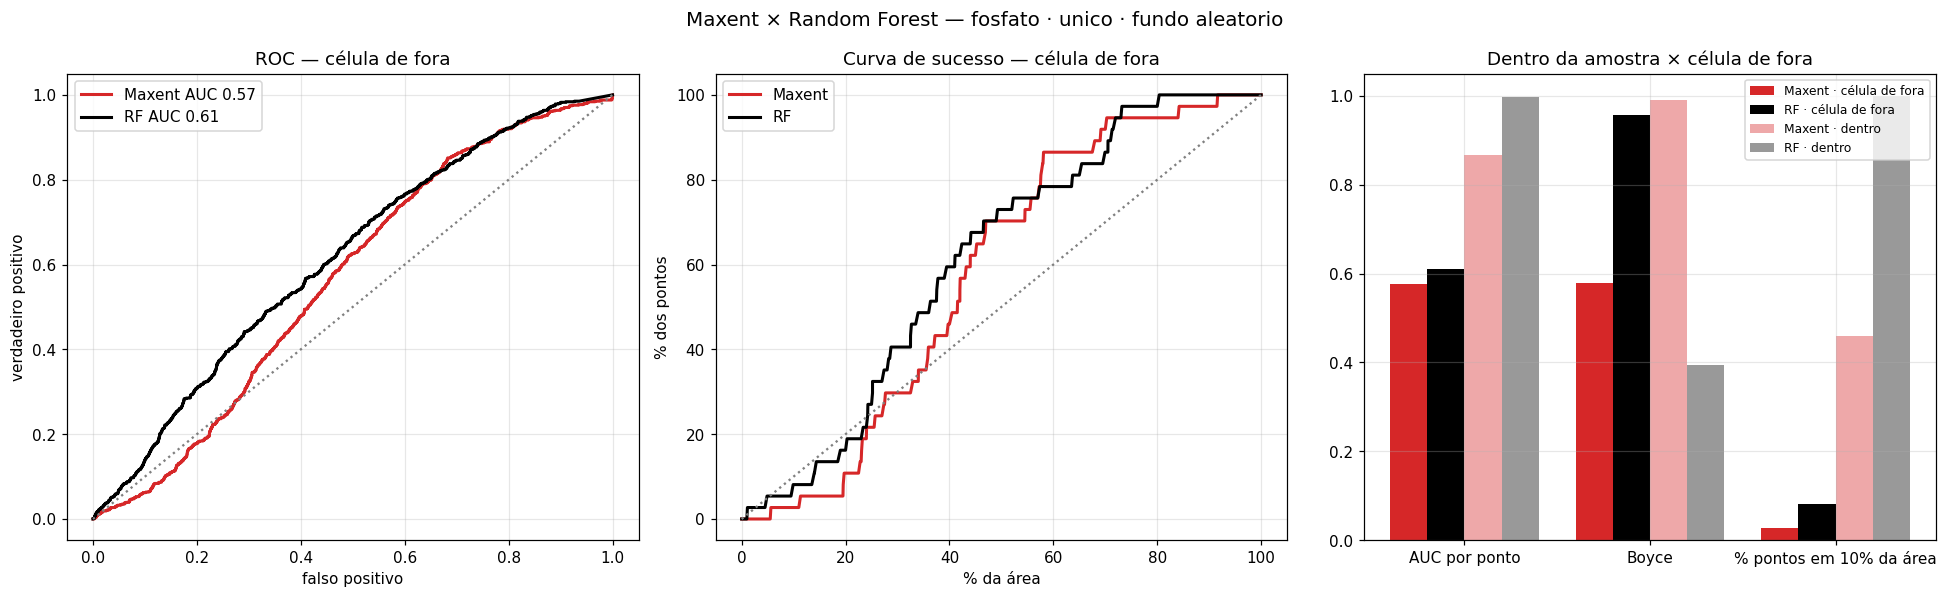

In [ ]:
# [13c]
from sklearn.ensemble import RandomForestClassifier

RF_PARAMS = dict(n_estimators=300, min_samples_leaf=10, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1, random_state=SEED)

class RFPresFundo:
    """Random Forest presença (1) × fundo (0), mesma interface do MaxentIWLR."""
    def fit(self, Xp, Xf):
        self.rf = RandomForestClassifier(**RF_PARAMS).fit(
            np.r_[Xp, Xf], np.r_[np.ones(len(Xp)), np.zeros(len(Xf))])
        return self
    def predict(self, X):
        return self.rf.predict_proba(X)[:, 1]

op_rf, of_rf = oof_por_celula(p, f, Modelo=RFPresFundo)
M_rf = metricas(op_rf, of_rf, p)
rf_in = RFPresFundo().fit(p[FEATURES].values, f[FEATURES].values)
M_rf_in = metricas(pd.Series(rf_in.predict(p[FEATURES].values), index=p.index),
                   pd.Series(rf_in.predict(f[FEATURES].values), index=f.index), p)

COMP_RF = pd.DataFrame({'Maxent · célula de fora': M, 'RF · célula de fora': M_rf,
                        'Maxent · dentro': M_in, 'RF · dentro': M_rf_in})

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))
y = np.r_[np.ones(len(op)), np.zeros(len(of))]
ax = axs[0]
for nome, (a_, b_), cor in [('Maxent', (op, of), cores[ALVO]), ('RF', (op_rf, of_rf), 'k')]:
    fpr, tpr, _ = roc_curve(y, np.r_[a_, b_])
    ax.plot(fpr, tpr, c=cor, lw=2, label=f'{nome} AUC {roc_auc_score(y, np.r_[a_, b_]):.2f}')
ax.plot([0, 1], [0, 1], ':', c='grey'); ax.legend(); ax.set_title('ROC — célula de fora')
ax.set_xlabel('falso positivo'); ax.set_ylabel('verdadeiro positivo')

ax = axs[1]
for nome, (a_, b_), cor in [('Maxent', (op, of), cores[ALVO]), ('RF', (op_rf, of_rf), 'k')]:
    ar, ca = sucesso(a_.groupby(p.CODIGO_OBJ).median().values, b_.values)
    ax.plot(ar * 100, ca * 100, c=cor, lw=2, label=nome)
ax.plot([0, 100], [0, 100], ':', c='grey'); ax.legend(); ax.set_title('Curva de sucesso — célula de fora')
ax.set_xlabel('% da área'); ax.set_ylabel('% dos pontos')

ax = axs[2]
mets = ['auc_ponto', 'boyce', 'pontos_top10pct_area']
x = np.arange(len(mets)); w = 0.2
for k, col in enumerate(COMP_RF.columns):
    ax.bar(x + (k - 1.5) * w, COMP_RF.loc[mets, col].astype(float), w, label=col,
           color=[cores[ALVO], 'k', cores[ALVO], 'k'][k], alpha=[1, 1, 0.4, 0.4][k])
ax.set_xticks(x, ['AUC por ponto', 'Boyce', '% pontos em 10% da área'])
ax.legend(fontsize=8); ax.set_title('Dentro da amostra × célula de fora')

fig.suptitle(f'Maxent × Random Forest — {ALVO} · {MOSAICO} · fundo {FUNDO}', fontsize=13)
fig.tight_layout()
salvar(fig, '13c', f'maxent_x_rf_{ALVO}_{MOSAICO}_{FUNDO}')
COMP_RF.round(3)

`[13d]`

### Gradient Tree Boosting (GTB)

Terceiro modelo, mesma validação. Árvores rasas adicionadas uma a uma, cada
uma corrigindo o erro das anteriores (`HistGradientBoostingClassifier`).
Em relação ao RF: costuma ser mais preciso com menos árvores, mas sobreajusta
mais fácil — por isso taxa de aprendizado baixa, folhas grandes
(`min_samples_leaf`), profundidade limitada e regularização L2. No GEE o
equivalente para o mapa é `ee.Classifier.smileGradientTreeBoost`.

A partir daqui `MODELOS_CLS` = {Maxent, RF, GTB} é usado nas células 24b, 25,
26 e na seção 9 (SHAP).

figura → c13e_maxent_rf_gtb_fosfato_unico_aleatorio.png


,Maxent · célula de fora,RF · célula de fora,GTB · célula de fora,Maxent · dentro,RF · dentro,GTB · dentro
auc_amostra,0.565,0.613,0.571,0.835,0.997,0.978
auc_ponto,0.578,0.611,0.579,0.866,0.998,0.986
boyce,0.578,0.957,0.768,0.991,0.395,0.843
pontos_top10pct_area,0.027,0.081,0.054,0.459,1.000,1.000
pontos_top25pct_area,0.216,0.270,0.270,0.865,1.000,1.000
auc_sucesso,0.579,0.612,0.580,0.867,0.998,0.986
n_pontos,37.000,37.000,37.000,37.000,37.000,37.000
n_celulas,5.000,5.000,5.000,5.000,5.000,5.000


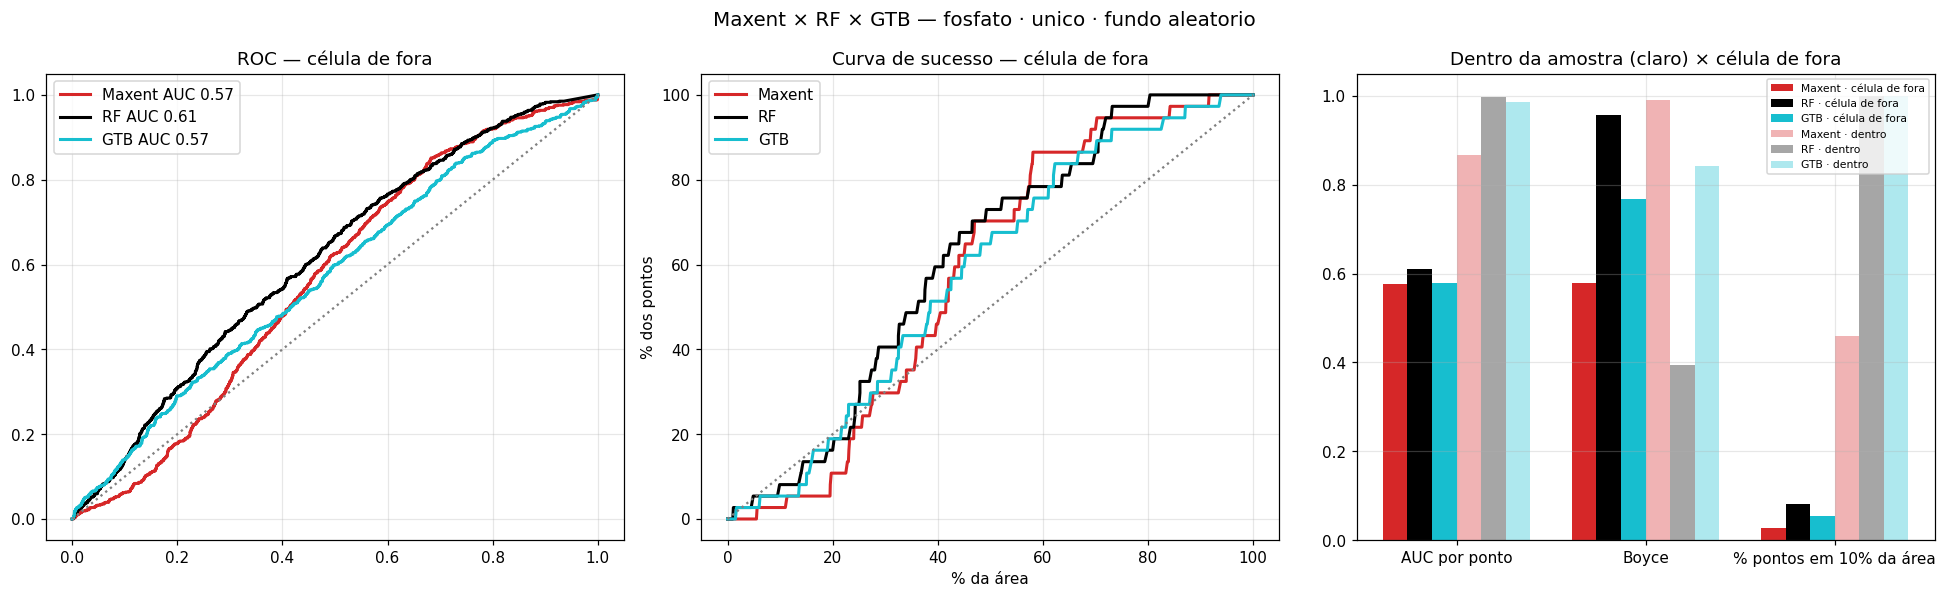

In [ ]:
# [13e]
from sklearn.ensemble import HistGradientBoostingClassifier

# 80 árvores e passo 0,1: o mesmo do exportar_favorabilidade_ml.py (no GEE, mais de ~90 fica pesado)
GTB_PARAMS = dict(learning_rate=0.1, max_iter=80, max_depth=4, min_samples_leaf=50,
                  l2_regularization=1.0, class_weight='balanced', random_state=SEED)

class GTBPresFundo:
    """Gradient Tree Boosting presença (1) × fundo (0), mesma interface do MaxentIWLR."""
    def fit(self, Xp, Xf):
        self.gb = HistGradientBoostingClassifier(**GTB_PARAMS).fit(
            np.r_[Xp, Xf], np.r_[np.ones(len(Xp)), np.zeros(len(Xf))])
        return self
    def predict(self, X):
        return self.gb.predict_proba(X)[:, 1]

MODELOS_CLS = {'Maxent': MaxentIWLR, 'RF': RFPresFundo, 'GTB': GTBPresFundo}
COR_MOD = {'Maxent': cores[ALVO], 'RF': 'k', 'GTB': '#17becf'}

op_gb, of_gb = oof_por_celula(p, f, Modelo=GTBPresFundo)
gb_in = GTBPresFundo().fit(p[FEATURES].values, f[FEATURES].values)
M_gb_in = metricas(pd.Series(gb_in.predict(p[FEATURES].values), index=p.index),
                   pd.Series(gb_in.predict(f[FEATURES].values), index=f.index), p)
OOF_MOD = {'Maxent': (op, of), 'RF': (op_rf, of_rf), 'GTB': (op_gb, of_gb)}
COMP_3 = pd.DataFrame({
    **{f'{k} · célula de fora': metricas(a_, b_, p) for k, (a_, b_) in OOF_MOD.items()},
    'Maxent · dentro': M_in, 'RF · dentro': M_rf_in, 'GTB · dentro': M_gb_in})

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))
y = np.r_[np.ones(len(op)), np.zeros(len(of))]
for k, (a_, b_) in OOF_MOD.items():
    fpr, tpr, _ = roc_curve(y, np.r_[a_, b_])
    axs[0].plot(fpr, tpr, c=COR_MOD[k], lw=2, label=f'{k} AUC {roc_auc_score(y, np.r_[a_, b_]):.2f}')
    ar, ca = sucesso(a_.groupby(p.CODIGO_OBJ).median().values, b_.values)
    axs[1].plot(ar * 100, ca * 100, c=COR_MOD[k], lw=2, label=k)
for ax, t in zip(axs[:2], ['ROC — célula de fora', 'Curva de sucesso — célula de fora']):
    ax.plot([0, 1] if 'ROC' in t else [0, 100], [0, 1] if 'ROC' in t else [0, 100], ':', c='grey')
    ax.legend(); ax.set_title(t)
axs[1].set_xlabel('% da área'); axs[1].set_ylabel('% dos pontos')

ax = axs[2]
mets = ['auc_ponto', 'boyce', 'pontos_top10pct_area']
x = np.arange(len(mets)); w = 0.13
for k, col in enumerate(COMP_3.columns):
    mod = col.split(' · ')[0]
    ax.bar(x + (k - 2.5) * w, COMP_3.loc[mets, col].astype(float), w, label=col, color=COR_MOD[mod],
           alpha=1 if 'fora' in col else 0.35)
ax.set_xticks(x, ['AUC por ponto', 'Boyce', '% pontos em 10% da área'])
ax.legend(fontsize=7); ax.set_title('Dentro da amostra (claro) × célula de fora')
fig.suptitle(f'Maxent × RF × GTB — {ALVO} · {MOSAICO} · fundo {FUNDO}', fontsize=13)
fig.tight_layout()
salvar(fig, '13e', f'maxent_rf_gtb_{ALVO}_{MOSAICO}_{FUNDO}')
COMP_3.round(3)

`[14]`

**Como ler.** AUC/Boyce dentro da amostra altos e na célula de fora perto de
0,5/0 = o modelo reconhece *onde* estão os pontos (assinatura local da cena,
do solo, da vegetação), mas não uma assinatura que se repete em outra célula.
É o resultado que importa para prospecção: o campo vai para áreas sem ponto.

## 4. Validação independente do fosfato (R2)

Treina **só com os pontos da bacia** (`papel = treino`) e testa nos pontos de
fora (`papel = validacao`, leste e norte), contra o fundo. É a pergunta "o
modelo de Irecê reconhece fosfato em outro lugar?". O contexto geológico fora
da bacia é diferente; AUC baixa aqui não invalida o modelo dentro da bacia.

treino: 13 pontos; validação: 24 pontos
auc_amostra              0.576
auc_ponto                0.605
boyce                    0.709
pontos_top10pct_area     0.000
pontos_top25pct_area     0.167
auc_sucesso              0.607
n_pontos                24.000
n_celulas                3.000


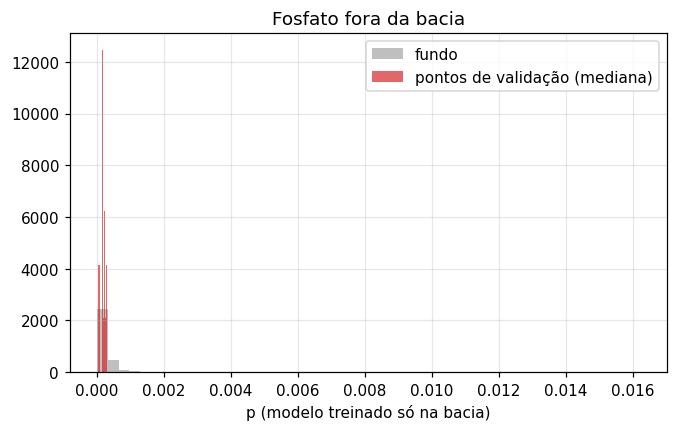

In [ ]:
# [15]
if ALVO == 'fosfato':
    pt, f2 = conjunto(df, 'fosfato', papeis=['treino'])
    pv, _ = conjunto(df, 'fosfato', papeis=['validacao'])
    m = MaxentIWLR().fit(pt[FEATURES].values, f2[FEATURES].values)
    ppv = pd.Series(m.predict(pv[FEATURES].values), index=pv.index)
    pfv = pd.Series(m.predict(f2[FEATURES].values), index=f2.index)
    R2 = metricas(ppv, pfv, pv)
    print(f'treino: {pt.CODIGO_OBJ.nunique()} pontos; validação: {pv.CODIGO_OBJ.nunique()} pontos')
    print(pd.Series(R2).round(3).to_string())
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(pfv, bins=50, density=True, alpha=0.5, color='grey', label='fundo')
    ax.hist(ppv.groupby(pv.CODIGO_OBJ).median(), bins=20, density=True, alpha=0.7, color=cores['fosfato'],
            label='pontos de validação (mediana)')
    ax.set_xlabel('p (modelo treinado só na bacia)'); ax.legend(); ax.set_title('Fosfato fora da bacia')
    salvar(fig, '15', 'validacao_R2_fosfato')
else:
    print('Só para o fosfato.')

`[16]`

## 5. Modelos nulos

A AUC real só significa algo se for maior que a de um modelo treinado com
"presenças" sem relação com o alvo. Dois nulos, mesmos números de pontos e de
amostras por ponto, mesma validação por célula:

- **aleatório**: pseudo-pontos sorteados em qualquer lugar da grid;
- **mesmas células**: pseudo-pontos sorteados só nas células que têm o alvo —
  desconta o quanto a AUC vem só de "onde" os pontos estão.

Pseudo-presenças = pixels de fundo sorteados (agrupados em pseudo-pontos pela
célula). Para caber no tempo, os nulos usam no máximo 5 células de fora.

figura → c17_nulos_fosfato_unico.png
aleatório: p-valor = 0.010
mesmas células: p-valor = 0.010


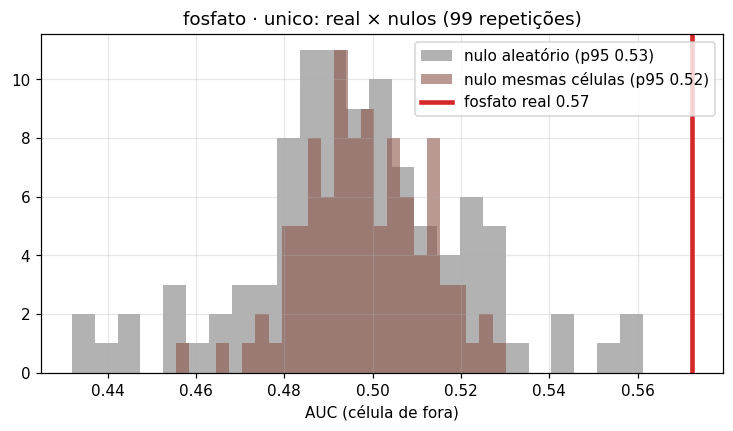

In [ ]:
# [17]
def auc_oof(p, f, max_celulas=None):
    cels = sorted(set(p.celula))
    if max_celulas and len(cels) > max_celulas:
        cels = list(rng.choice(cels, max_celulas, replace=False))
    sp, sf = [], []
    for c in cels:
        m = MaxentIWLR().fit(p.loc[p.celula != c, FEATURES].values, f.loc[f.celula != c, FEATURES].values)
        sp.append(m.predict(p.loc[p.celula == c, FEATURES].values))
        sf.append(m.predict(f.loc[f.celula == c, FEATURES].values))
    sp, sf = np.concatenate(sp), np.concatenate(sf)
    return roc_auc_score(np.r_[np.ones(len(sp)), np.zeros(len(sf))], np.r_[sp, sf])

def pseudo(f, n, celulas=None):
    base = f if celulas is None else f[f.celula.isin(celulas)]
    idx = rng.choice(base.index, n, replace=False)
    return base.loc[idx].assign(classe=1), f.drop(idx)

n = len(p)
real = auc_oof(p, f, max_celulas=5)
nulos = {'aleatório': [], 'mesmas células': []}
for i in range(N_NULO):
    for nome, cels in [('aleatório', None), ('mesmas células', sorted(p.celula.unique()))]:
        pp_, ff_ = pseudo(f, min(n, len(f) // 3), cels)
        nulos[nome].append(auc_oof(pp_, ff_, max_celulas=5))

fig, ax = plt.subplots(figsize=(8, 4))
for (nome, v), cor in zip(nulos.items(), ['grey', '#8c564b']):
    ax.hist(v, bins=25, alpha=0.6, color=cor, label=f'nulo {nome} (p95 {np.percentile(v, 95):.2f})')
ax.axvline(real, c=cores[ALVO], lw=3, label=f'{ALVO} real {real:.2f}')
ax.set_xlabel('AUC (célula de fora)'); ax.legend(); ax.set_title(f'{ALVO} · {MOSAICO}: real × nulos ({N_NULO} repetições)')
salvar(fig, '17', f'nulos_{ALVO}_{MOSAICO}')
for nome, v in nulos.items():
    print(f'{nome}: p-valor = {(np.sum(np.array(v) >= real) + 1) / (len(v) + 1):.3f}')

`[18]`

## 6. Interpretação

- **Importância por permutação**: queda da AUC OOF quando se embaralha uma
  feature nas amostras de teste (sem retreinar).
- **Curvas de resposta**: *p* variando uma feature (p1–p99 do fundo) com as
  outras na mediana do fundo.
- **Redundância**: pares de features com |r| > 0,9 no fundo.

figura → c19_importancia_fosfato_unico.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c19_importancia_fosfato_unico.png')

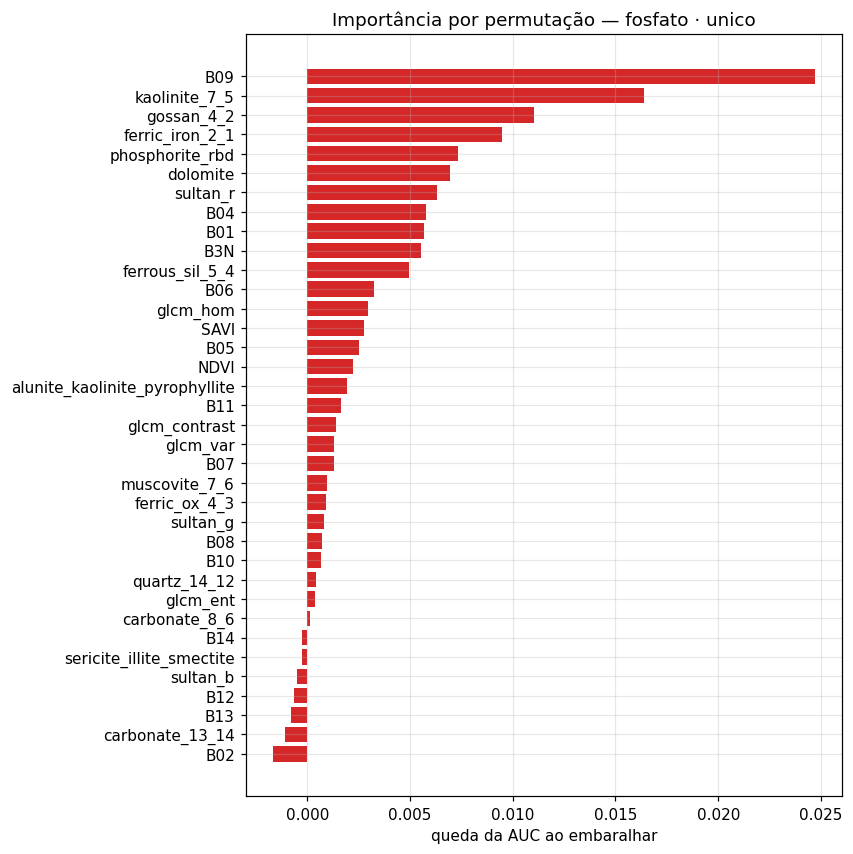

In [ ]:
# [19]
modelo = MaxentIWLR().fit(p[FEATURES].values, f[FEATURES].values)
Xp, Xf = p[FEATURES].values.copy(), f[FEATURES].values.copy()
y = np.r_[np.ones(len(Xp)), np.zeros(len(Xf))]
base_auc = roc_auc_score(y, np.r_[op, of])
imp = {}
for j, c in enumerate(FEATURES):
    quedas = []
    for _ in range(5):
        Xpp, Xff = Xp.copy(), Xf.copy()
        tudo = np.r_[Xpp[:, j], Xff[:, j]]
        rng.shuffle(tudo)
        Xpp[:, j], Xff[:, j] = tudo[:len(Xpp)], tudo[len(Xpp):]
        quedas.append(roc_auc_score(y, np.r_[modelo.predict(Xp), modelo.predict(Xf)])
                      - roc_auc_score(y, np.r_[modelo.predict(Xpp), modelo.predict(Xff)]))
    imp[c] = np.mean(quedas)
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(imp.index, imp.values, color=cores[ALVO])
ax.set_xlabel('queda da AUC ao embaralhar'); ax.set_title(f'Importância por permutação — {ALVO} · {MOSAICO}')
salvar(fig, '19', f'importancia_{ALVO}_{MOSAICO}')

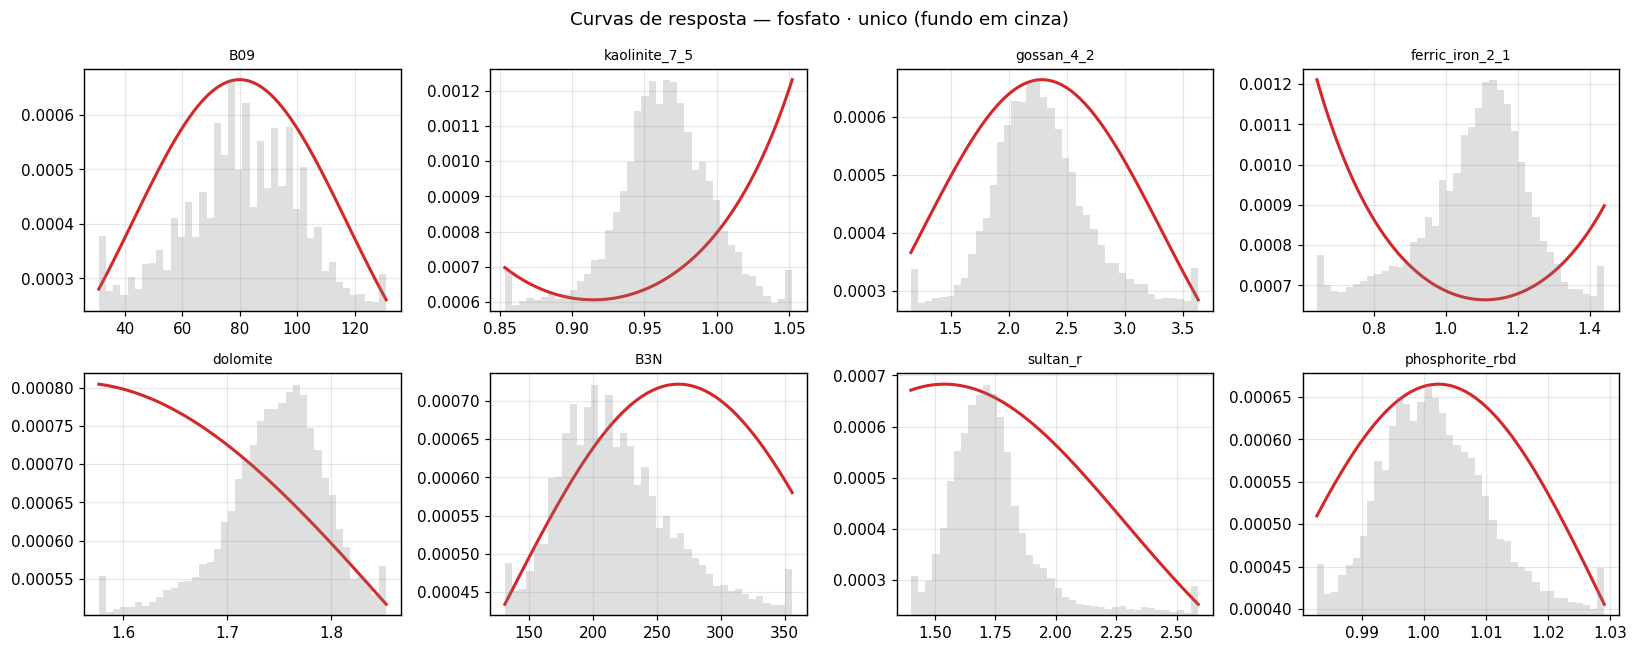

In [ ]:
# [20]
top = imp.index[::-1][:8]
med = f[FEATURES].median().values
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axs.flat, top):
    j = FEATURES.index(c)
    xs = np.linspace(*np.nanpercentile(f[c], [1, 99]), 100)
    X = np.tile(med, (100, 1)); X[:, j] = xs
    ax.plot(xs, modelo.predict(X), c=cores[ALVO], lw=2)
    ax2 = ax.twinx(); ax2.hist(f[c].clip(xs[0], xs[-1]), bins=40, color='grey', alpha=0.25); ax2.set_yticks([])
    ax.set_title(c, fontsize=9)
fig.suptitle(f'Curvas de resposta — {ALVO} · {MOSAICO} (fundo em cinza)'); fig.tight_layout()
salvar(fig, '20', f'resposta_{ALVO}_{MOSAICO}')

,level_0,level_1,r
279,B11,B12,0.997
330,B13,B14,0.997
102,B05,B06,0.996
252,B10,B11,0.994
103,B05,B07,0.993
280,B11,B13,0.993
165,B07,B08,0.991
134,B06,B07,0.991
104,B05,B08,0.991
305,B12,B13,0.990


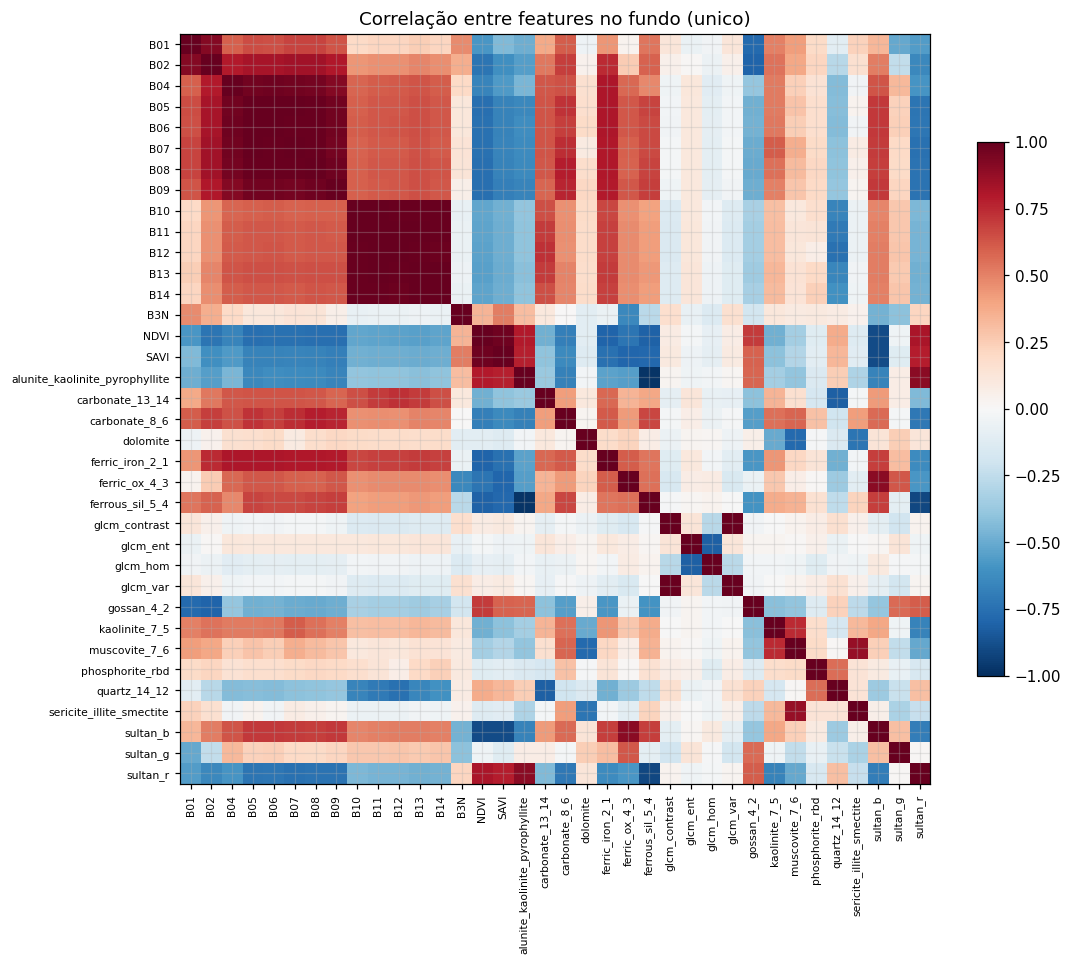

In [ ]:
# [21]
corr = f[FEATURES].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
fig.colorbar(im, shrink=0.7); ax.set_title(f'Correlação entre features no fundo ({MOSAICO})')
salvar(fig, '21', f'correlacao_features_{MOSAICO}')
pares = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
             .rename('r').reset_index().loc[lambda t: t.r.abs() > 0.9].sort_values('r', key=abs, ascending=False))
pares.round(3)

`[22]`

## 7. Comparação entre alvos e mosaicos

Mesma validação por célula para os 5 alvos nos 2 mosaicos (Maxent em 23–24,
RF e GTB em 24b). Depois, com **os três modelos**:
- **[25]** correlação entre os *p* dos alvos no fundo — alvos muito
  correlacionados não acrescentam informação um ao outro como covariável;
- **[26]** fosfato **com e sem** *p*(outros alvos) como covariável. Os *p* dos
  outros alvos são calculados com modelos treinados nos pontos deles (rótulos
  diferentes do fosfato), fora da amostra por célula. Combina o modelo que
  gera os *p* (Maxent, RF ou GTB) com o modelo do fosfato (idem). *p* ou
  1 − *p* dá o mesmo resultado nos dois modelos — no Maxent só muda o sinal
  do coeficiente; nas árvores os cortes são os mesmos.

In [ ]:
# [23]
linhas, OOF = [], {}
for mos, d in DADOS.items():
    for a in ALVOS:
        pa, fa = conjunto(d, a)
        opa, ofa = oof_por_celula(pa, fa)
        OOF[(mos, a)] = (opa, ofa, pa)
        linhas.append({'mosaico': mos, 'alvo': a, 'fundo': FUNDO, **metricas(opa, ofa, pa)})
        print(f'{mos:6s} {a:10s} AUC {linhas[-1]["auc_amostra"]:.3f}  Boyce {linhas[-1]["boyce"]:.2f}')
TAB = pd.DataFrame(linhas)
TAB.round(3)

unico  fosfato    AUC 0.565  Boyce 0.58
unico  carbonato  AUC 0.593  Boyce 0.81
unico  mvt        AUC 0.666  Boyce 1.00
unico  ouro       AUC 0.357  Boyce -0.90
unico  manganes   AUC 0.626  Boyce 0.98
v1     fosfato    AUC 0.686  Boyce 0.78
v1     carbonato  AUC 0.634  Boyce 0.99
v1     mvt        AUC 0.597  Boyce 0.94
v1     ouro       AUC 0.552  Boyce 0.61
v1     manganes   AUC 0.629  Boyce 0.94


,mosaico,alvo,fundo,auc_amostra,auc_ponto,boyce,pontos_top10pct_area,pontos_top25pct_area,auc_sucesso,n_pontos,n_celulas
0,unico,fosfato,aleatorio,0.565,0.578,0.578,0.027,0.216,0.579,37,5
1,unico,carbonato,aleatorio,0.593,0.604,0.808,0.131,0.315,0.605,327,23
2,unico,mvt,aleatorio,0.666,0.683,0.998,0.143,0.448,0.684,252,20
3,unico,ouro,aleatorio,0.357,0.343,-0.903,0.029,0.082,0.344,208,14
4,unico,manganes,aleatorio,0.626,0.637,0.984,0.204,0.439,0.638,269,20
5,v1,fosfato,aleatorio,0.686,0.695,0.777,0.054,0.378,0.696,37,5
6,v1,carbonato,aleatorio,0.634,0.636,0.986,0.135,0.346,0.637,327,23
7,v1,mvt,aleatorio,0.597,0.611,0.942,0.131,0.413,0.612,252,20
8,v1,ouro,aleatorio,0.552,0.561,0.610,0.024,0.173,0.562,208,14
9,v1,manganes,aleatorio,0.629,0.640,0.941,0.160,0.401,0.641,269,20


figura → c24_comparacao_alvos_mosaicos_aleatorio.png
figura → c24_sucesso_alvos_aleatorio.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c24_sucesso_alvos_aleatorio.png')

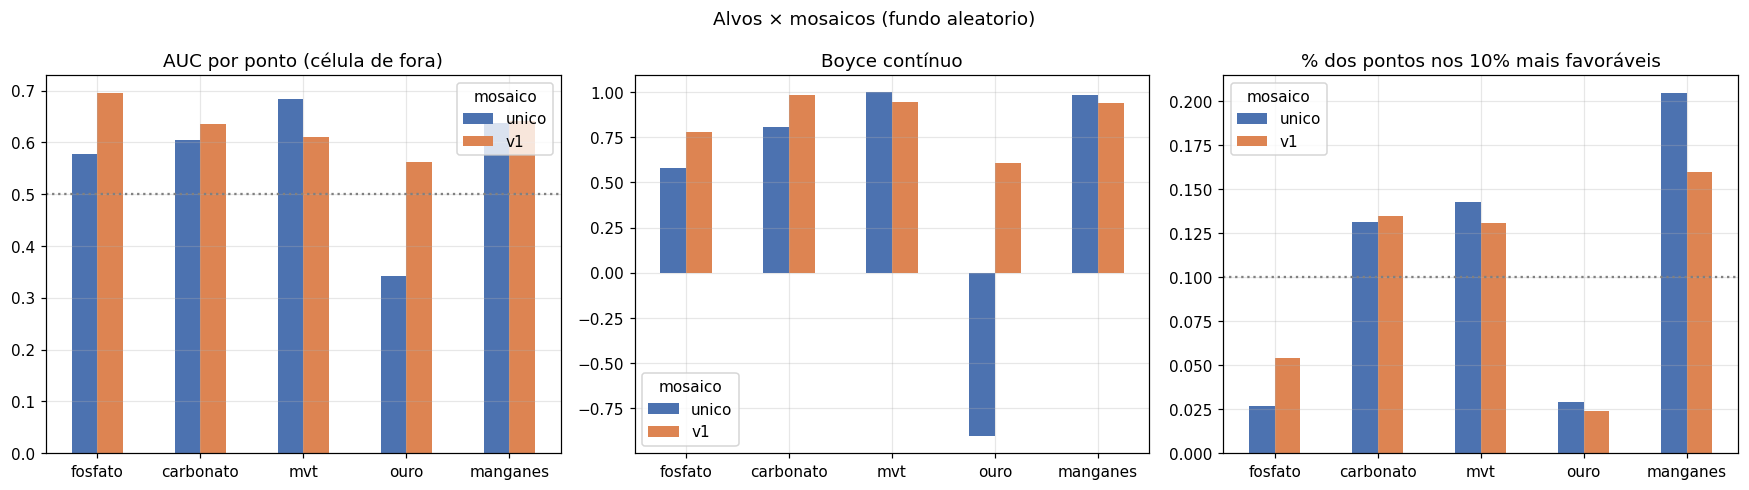

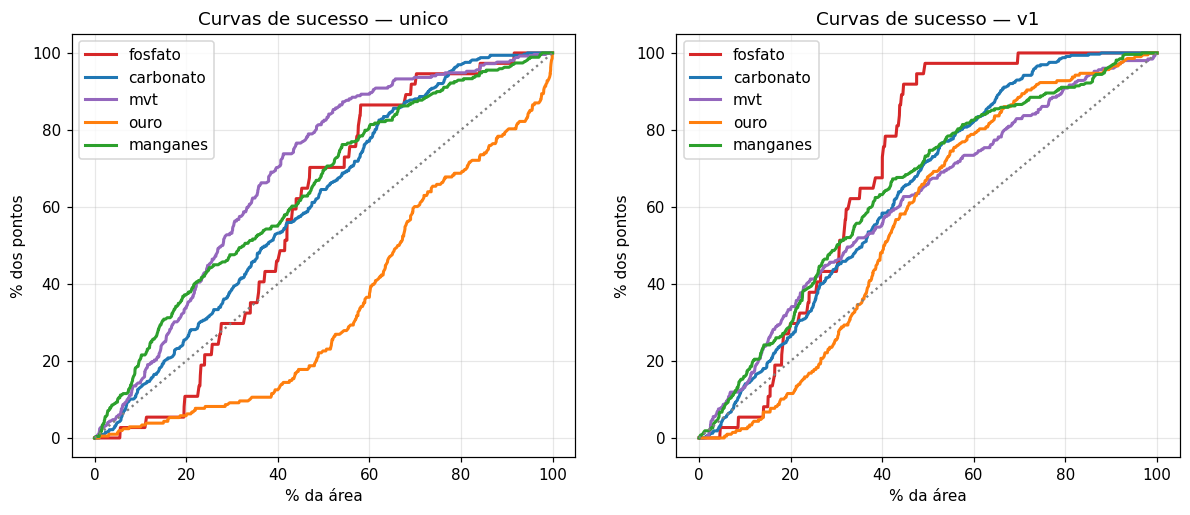

In [ ]:
# [24]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, met, tit in zip(axs, ['auc_ponto', 'boyce', 'pontos_top10pct_area'],
                        ['AUC por ponto (célula de fora)', 'Boyce contínuo', '% dos pontos nos 10% mais favoráveis']):
    t = TAB.pivot(index='alvo', columns='mosaico', values=met).loc[ALVOS]
    t.plot.bar(ax=ax, color=['#4c72b0', '#dd8452'], rot=0)
    ax.set_title(tit); ax.set_xlabel('')
    if met == 'auc_ponto': ax.axhline(0.5, c='grey', ls=':')
    if met == 'pontos_top10pct_area': ax.axhline(0.10, c='grey', ls=':')
fig.suptitle(f'Alvos × mosaicos (fundo {FUNDO})'); fig.tight_layout()
salvar(fig, '24', f'comparacao_alvos_mosaicos_{FUNDO}')

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, mos in zip(axs, DADOS):
    for a in ALVOS:
        opa, ofa, pa = OOF[(mos, a)]
        ar, ca = sucesso(opa.groupby(pa.CODIGO_OBJ).median().values, ofa.values)
        ax.plot(ar * 100, ca * 100, c=cores[a], lw=2, label=a)
    ax.plot([0, 100], [0, 100], ':', c='grey'); ax.set_title(f'Curvas de sucesso — {mos}')
    ax.set_xlabel('% da área'); ax.set_ylabel('% dos pontos'); ax.legend()
salvar(fig, '24', f'sucesso_alvos_{FUNDO}')

RF   unico  fosfato    AUC 0.613  Boyce 0.96
RF   unico  carbonato  AUC 0.643  Boyce 0.98
RF   unico  mvt        AUC 0.685  Boyce 1.00
RF   unico  ouro       AUC 0.466  Boyce -0.64
RF   unico  manganes   AUC 0.686  Boyce 0.99
RF   v1     fosfato    AUC 0.818  Boyce 0.98
RF   v1     carbonato  AUC 0.632  Boyce 0.88
RF   v1     mvt        AUC 0.661  Boyce 0.99
RF   v1     ouro       AUC 0.627  Boyce 0.90
RF   v1     manganes   AUC 0.617  Boyce 0.95
GTB  unico  fosfato    AUC 0.571  Boyce 0.77
GTB  unico  carbonato  AUC 0.646  Boyce 0.99
GTB  unico  mvt        AUC 0.698  Boyce 1.00
GTB  unico  ouro       AUC 0.516  Boyce 0.26
GTB  unico  manganes   AUC 0.690  Boyce 1.00
GTB  v1     fosfato    AUC 0.795  Boyce 0.99
GTB  v1     carbonato  AUC 0.658  Boyce 1.00
GTB  v1     mvt        AUC 0.653  Boyce 0.99
GTB  v1     ouro       AUC 0.648  Boyce 0.92
GTB  v1     manganes   AUC 0.640  Boyce 0.99
figura → c24b_maxent_rf_gtb_alvos_aleatorio.png


mosaico    unico                   v1              
modelo       GTB Maxent     RF    GTB Maxent     RF
alvo                                               
fosfato    0.579  0.578  0.611  0.809  0.695  0.834
carbonato  0.665  0.604  0.659  0.665  0.636  0.636
mvt        0.719  0.683  0.705  0.667  0.611  0.676
ouro       0.513  0.343  0.457  0.652  0.561  0.629
manganes   0.710  0.637  0.704  0.655  0.640  0.622

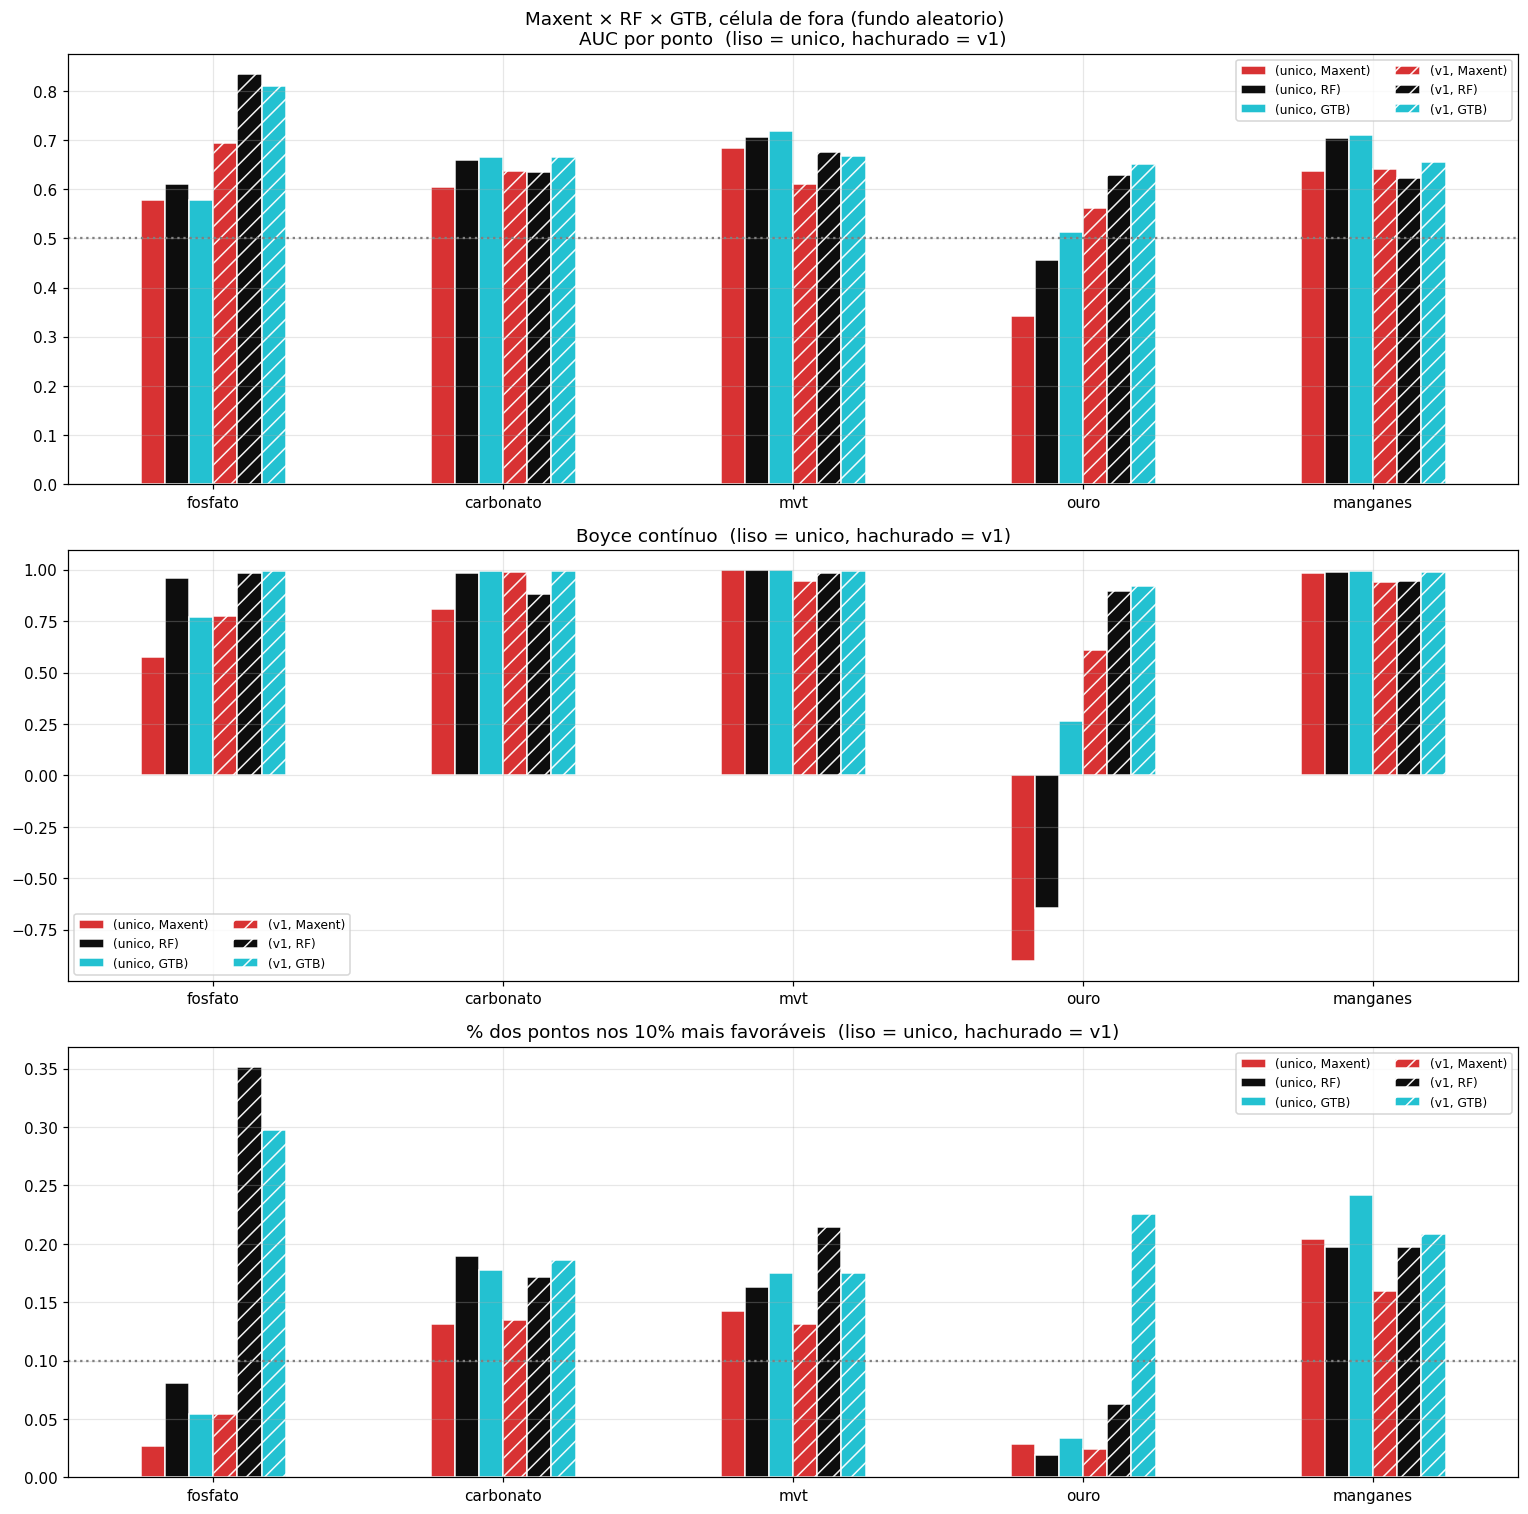

In [ ]:
# [24b]
# Maxent × RF × GTB para todos os alvos e mosaicos (célula de fora). O RF é o
# mais lento: 2 mosaicos × 5 alvos × 25 células = 250 florestas.
linhas_mod = []
for nome_mod in ['RF', 'GTB']:
    for mos, d in DADOS.items():
        for a in ALVOS:
            pa, fa = conjunto(d, a)
            o1, o2 = oof_por_celula(pa, fa, Modelo=MODELOS_CLS[nome_mod])
            linhas_mod.append({'modelo': nome_mod, 'mosaico': mos, 'alvo': a, 'fundo': FUNDO,
                               **metricas(o1, o2, pa)})
            print(f'{nome_mod:4s} {mos:6s} {a:10s} AUC {linhas_mod[-1]["auc_amostra"]:.3f}  '
                  f'Boyce {linhas_mod[-1]["boyce"]:.2f}')
TAB_MOD = pd.concat([TAB.assign(modelo='Maxent'), pd.DataFrame(linhas_mod)], ignore_index=True)

fig, axs = plt.subplots(3, 1, figsize=(14, 14))
for ax, met, tit in zip(axs, ['auc_ponto', 'boyce', 'pontos_top10pct_area'],
                        ['AUC por ponto', 'Boyce contínuo', '% dos pontos nos 10% mais favoráveis']):
    t = TAB_MOD.pivot_table(index='alvo', columns=['mosaico', 'modelo'], values=met).loc[ALVOS]
    t = t[[(m, k) for m in DADOS for k in MODELOS_CLS]]
    t.plot.bar(ax=ax, rot=0, color=[COR_MOD[k] for _ in DADOS for k in MODELOS_CLS],
               edgecolor='w', alpha=0.95)
    for barras, (m, _) in zip(ax.containers, t.columns):
        if m == 'v1':
            for b in barras: b.set_hatch('//')
    ax.set_title(tit + '  (liso = unico, hachurado = v1)'); ax.set_xlabel(''); ax.legend(fontsize=8, ncol=2)
    if met == 'auc_ponto': ax.axhline(0.5, c='grey', ls=':')
    if met == 'pontos_top10pct_area': ax.axhline(0.10, c='grey', ls=':')
fig.suptitle(f'Maxent × RF × GTB, célula de fora (fundo {FUNDO})'); fig.tight_layout()
salvar(fig, '24b', f'maxent_rf_gtb_alvos_{FUNDO}')
TAB_MOD.pivot_table(index='alvo', columns=['mosaico', 'modelo'], values='auc_ponto').loc[ALVOS].round(3)

figura → c25_correlacao_entre_alvos.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c25_correlacao_entre_alvos.png')

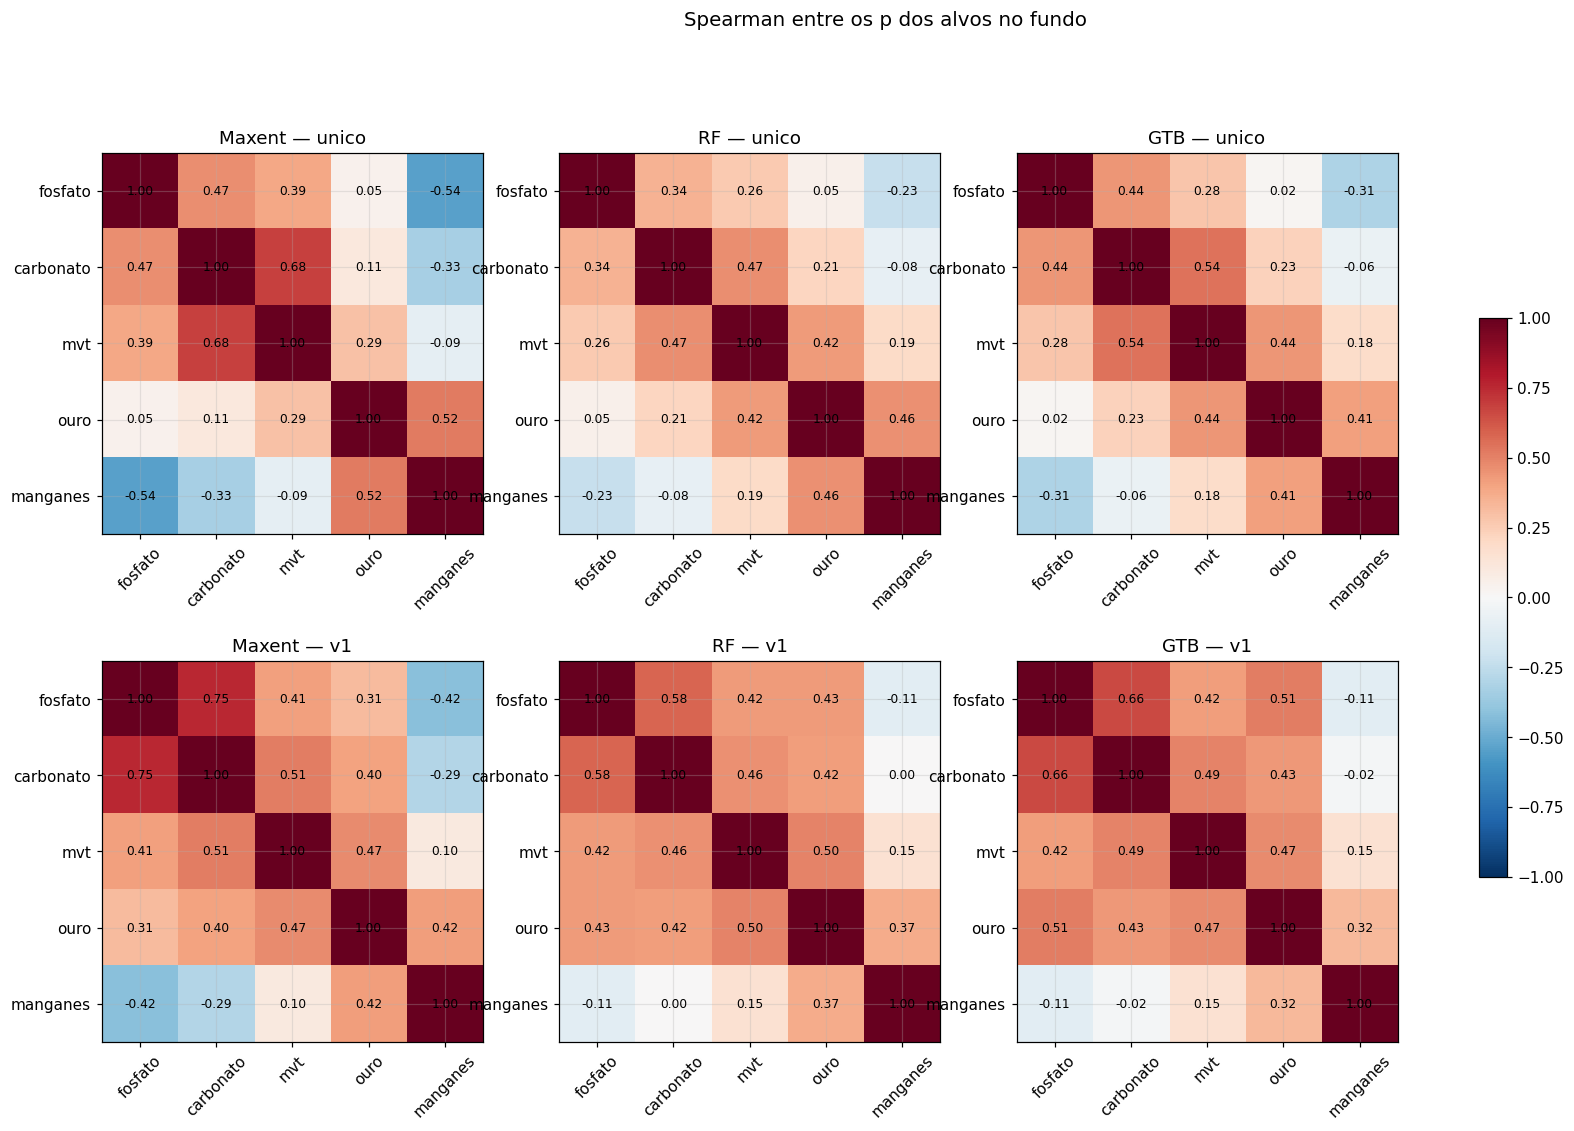

In [ ]:
# [25]
# p de cada alvo no fundo (modelo com todos os pontos do alvo) → correlação entre alvos,
# para Maxent, RF e GTB (MODELOS_CLS da célula 13e)
P_FUNDO = {}   # (modelo, mosaico) → DataFrame fundo × alvo
for nome_mod, Cls in MODELOS_CLS.items():
    for mos, d in DADOS.items():
        fd = d[d.classe == 0]
        cols = {}
        for a in ALVOS:
            pa, fa = conjunto(d, a)
            cols[a] = Cls().fit(pa[FEATURES].values, fa[FEATURES].values).predict(fd[FEATURES].values)
        P_FUNDO[(nome_mod, mos)] = pd.DataFrame(cols, index=fd.index)

fig, axs = plt.subplots(len(DADOS), len(MODELOS_CLS), figsize=(19, 11))
for ax, (nome_mod, mos) in zip(axs.T.flat, P_FUNDO):
    c = P_FUNDO[(nome_mod, mos)].corr(method='spearman')
    im = ax.imshow(c, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(ALVOS)), ALVOS, rotation=45); ax.set_yticks(range(len(ALVOS)), ALVOS)
    for i in range(len(ALVOS)):
        for j in range(len(ALVOS)):
            ax.text(j, i, f'{c.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
    ax.set_title(f'{nome_mod} — {mos}')
fig.colorbar(im, ax=axs, shrink=0.6)
fig.suptitle('Spearman entre os p dos alvos no fundo', fontsize=13)
salvar(fig, '25', 'correlacao_entre_alvos')


unico: p(outros) por Maxent pronto
unico: p(outros) por RF pronto
unico: p(outros) por GTB pronto
v1: p(outros) por Maxent pronto
v1: p(outros) por RF pronto
v1: p(outros) por GTB pronto
figura → c26_fosfato_covariaveis_p_outros.png


,mosaico,modelo_fosfato,modelo_p,features,auc_ponto,boyce,pontos_top10pct_area
19,unico,GTB,GTB,ASTER + p(outros),0.560,0.837,0.054
7,unico,GTB,Maxent,ASTER + p(outros),0.514,0.240,0.054
13,unico,GTB,RF,ASTER + p(outros),0.541,0.501,0.054
2,unico,GTB,—,só ASTER,0.579,0.768,0.054
20,unico,GTB,GTB,só p(outros),0.537,0.413,0.027
8,unico,GTB,Maxent,só p(outros),0.318,-0.853,0.054
14,unico,GTB,RF,só p(outros),0.365,-0.832,0.000
15,unico,Maxent,GTB,ASTER + p(outros),0.573,0.469,0.027
3,unico,Maxent,Maxent,ASTER + p(outros),0.556,0.469,0.027
9,unico,Maxent,RF,ASTER + p(outros),0.548,0.413,0.027


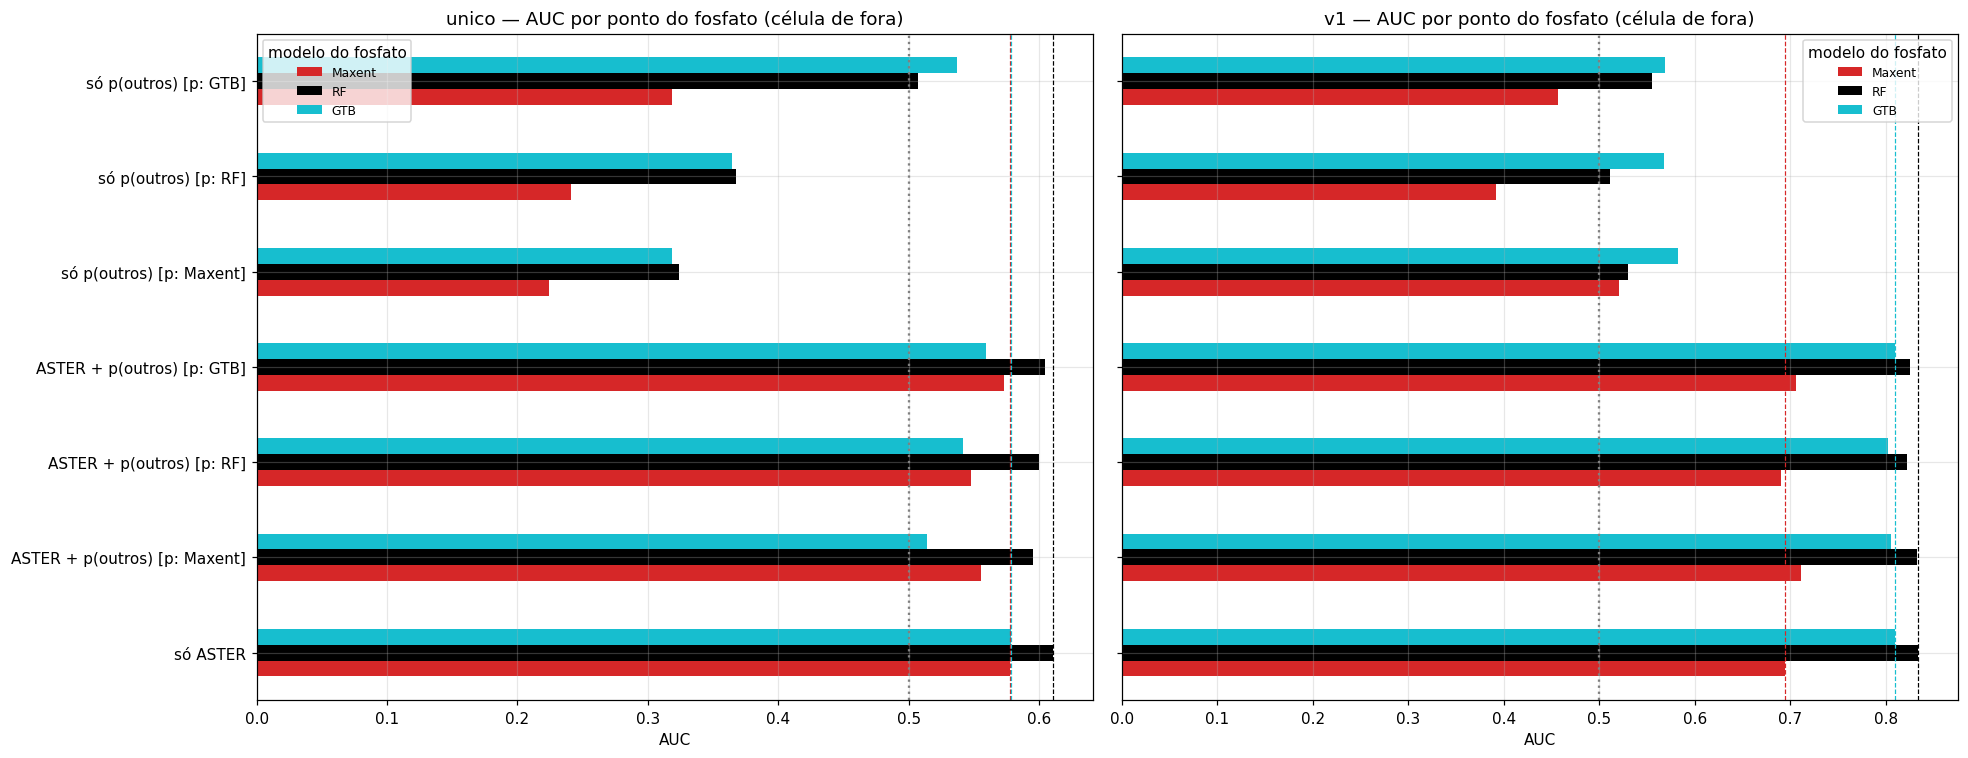

In [ ]:
# [26]
# fosfato com e sem p(outros alvos) como covariável — Maxent, RF e GTB nos dois papéis:
#   modelo_p        quem gera p(carbonato), p(mvt), p(ouro), p(manganes)
#   modelo_fosfato  quem modela o fosfato com essas features
# A mais lenta do notebook: cada modelo treina 4 alvos × 25 células por mosaico só para os p.
outros = [a for a in ALVOS if a != 'fosfato']
cols_p = [f'p_{a}' for a in outros]

def p_outros_oof(d, Cls):
    """p de cada outro alvo, fora da amostra por célula (não vaza a posição)."""
    d2 = d.copy()
    for a in outros:
        pa, fa = conjunto(d, a)
        col = pd.Series(np.nan, index=d.index)
        for c in sorted(d.celula.unique()):
            m = Cls().fit(pa.loc[pa.celula != c, FEATURES].values, fa.loc[fa.celula != c, FEATURES].values)
            col[d.celula == c] = m.predict(d.loc[d.celula == c, FEATURES].values)
        d2[f'p_{a}'] = col
    return d2

comp = []
for mos, d in DADOS.items():
    # só ASTER não depende de modelo_p
    pf_, ff_ = conjunto(d, 'fosfato')
    for mod_f, ClsF in MODELOS_CLS.items():
        o1, o2 = oof_por_celula(pf_, ff_, FEATURES, Modelo=ClsF)
        comp.append({'mosaico': mos, 'modelo_p': '—', 'modelo_fosfato': mod_f, 'features': 'só ASTER',
                     **metricas(o1, o2, pf_)})
    for mod_p, ClsP in MODELOS_CLS.items():
        d2 = p_outros_oof(d, ClsP)
        pf_, ff_ = conjunto(d2, 'fosfato')
        for mod_f, ClsF in MODELOS_CLS.items():
            for nome, feats in [('ASTER + p(outros)', FEATURES + cols_p), ('só p(outros)', cols_p)]:
                o1, o2 = oof_por_celula(pf_, ff_, feats, Modelo=ClsF)
                comp.append({'mosaico': mos, 'modelo_p': mod_p, 'modelo_fosfato': mod_f, 'features': nome,
                             **metricas(o1, o2, pf_)})
        print(f'{mos}: p(outros) por {mod_p} pronto')
COMP = pd.DataFrame(comp)

# gráfico: AUC por ponto do fosfato, por mosaico e modelo do fosfato
COMP['config'] = np.where(COMP.features == 'só ASTER', 'só ASTER',
                          COMP.features + ' [p: ' + COMP.modelo_p + ']')
ordem = ['só ASTER'] + [f'{f_} [p: {k}]' for f_ in ['ASTER + p(outros)', 'só p(outros)'] for k in MODELOS_CLS]
fig, axs = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
for ax, mos in zip(axs, DADOS):
    t = (COMP[COMP.mosaico == mos].pivot(index='config', columns='modelo_fosfato', values='auc_ponto')
             .reindex(ordem))
    t = t[list(MODELOS_CLS)]
    t.plot.barh(ax=ax, color=[COR_MOD[k] for k in t.columns])
    ax.axvline(0.5, c='grey', ls=':')
    base = t.loc['só ASTER']
    for k, col in enumerate(t.columns):
        ax.axvline(base[col], c=COR_MOD[col], ls='--', lw=0.8)
    ax.set_title(f'{mos} — AUC por ponto do fosfato (célula de fora)'); ax.set_xlabel('AUC'); ax.set_ylabel('')
    ax.legend(title='modelo do fosfato', fontsize=8)
fig.tight_layout()
salvar(fig, '26', 'fosfato_covariaveis_p_outros')
COMP[['mosaico', 'modelo_fosfato', 'modelo_p', 'features', 'auc_ponto', 'boyce',
      'pontos_top10pct_area']].sort_values(['mosaico', 'modelo_fosfato', 'features', 'modelo_p']).round(3)


`[27]`

## 8. Resumo

In [ ]:
# [28]
from datetime import date
arq = MODELS / f'avaliacao_maxent_{date.today():%Y%m%d}_{FUNDO}.csv'
TAB.to_csv(arq, index=False)
COMP.to_csv(arq.with_name(arq.stem + '_fosfato_covariaveis.csv'), index=False)
TAB_MOD.to_csv(arq.with_name(arq.stem + '_maxent_x_rf.csv'), index=False)
print(f'→ {arq}\n→ figuras em {FIGS}')
TAB.pivot(index='alvo', columns='mosaico', values=['auc_ponto', 'boyce', 'pontos_top10pct_area']).loc[ALVOS].round(3)

→ /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/avaliacao_maxent_20261021_aleatorio.csv
→ figuras em /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent


auc_ponto         boyce        pontos_top10pct_area       
mosaico       unico     v1  unico     v1                unico     v1
alvo                                                                
fosfato       0.578  0.695  0.578  0.777                0.027  0.054
carbonato     0.604  0.636  0.808  0.986                0.131  0.135
mvt           0.683  0.611  0.998  0.942                0.143  0.131
ouro          0.343  0.561 -0.903  0.610                0.029  0.024
manganes      0.637  0.640  0.984  0.941                0.204  0.160

`[29]`

## 9. SHAP — ranking das variáveis para um modelo de deep learning

**SHAP** (SHapley Additive exPlanations; Lundberg & Lee 2017) reparte a
predição de cada amostra entre as features: para um pixel, o valor SHAP de
`B07` é quanto a B07 empurrou a pontuação para cima ou para baixo em relação à
média. A soma dos SHAP de todas as features + a média = a predição do pixel.
O **|SHAP| médio** de uma feature é a sua importância.

Diferenças em relação à permutação da célula 19: o SHAP mostra a **direção**
(valor alto da feature → sobe ou desce *p*), funciona por amostra e divide de
forma justa o efeito entre features correlacionadas.

**Como o ranking é montado (para servir a um modelo novo):**
1. SHAP **fora da amostra**: as células são divididas em `N_FOLDS` grupos;
   treina em 4 grupos e calcula o SHAP nas amostras do grupo deixado de fora.
   Uma feature só sobe no ranking se ajudar em células que o modelo não viu.
2. Modelos de árvore (RF e GTB, `TreeExplainer` — exato e rápido). O Maxent
   fica com a permutação da célula 19.
3. Para cada alvo × mosaico × modelo, importância normalizada (soma = 1);
   o ranking final é a **média dos postos** em todas as combinações, com a
   dispersão — feature boa só num alvo ou num mosaico aparece com dispersão alta.
4. **Seleção sem redundância**: desce o ranking e descarta a feature com
   |r| > `R_MAX` com uma já escolhida (correlação no fundo, célula 21).

**Para o deep learning:** a lista final (`FEATURES_DL`) é o conjunto de
entrada sugerido. Redes aprendem interações sozinhas, então o mais útil é
tirar redundância e ruído — com ~1.100 pontos, menos entradas = menos
sobreajuste. Vale manter as bandas brutas mais importantes junto dos
índices: a rede pode reconstruir razões que não estão na lista.

Requer o pacote `shap` (`pip install shap`). Tempo: o RF é o mais lento —
reduza `SHAP_N` ou tire o RF de `SHAP_MODELOS` para testar.

In [ ]:
# [30]
try:
    import shap
except ImportError:
    raise ImportError('Instale o shap: no terminal, pip install shap (ou %pip install shap aqui) e reinicie o kernel.')
from sklearn.model_selection import GroupKFold

SHAP_MODELOS = ['GTB', 'RF']   # modelos de árvore
SHAP_ALVOS = ALVOS
N_FOLDS = 5
SHAP_N = 400                   # amostras explicadas por fold (metade presença, metade fundo)
R_MAX = 0.9                    # correlação máxima entre features escolhidas

def shap_arvore(modelo, X):
    """|SHAP| da classe presença para RF (sklearn) ou GTB (HistGradientBoosting)."""
    est = modelo.rf if hasattr(modelo, 'rf') else modelo.gb
    sv = shap.TreeExplainer(est).shap_values(X, check_additivity=False)
    if isinstance(sv, list):          # versões antigas: uma matriz por classe
        sv = sv[1]
    if sv.ndim == 3:                  # (amostras, features, classes)
        sv = sv[..., 1]
    return sv

def shap_fora_da_amostra(d, alvo, nome_mod):
    """SHAP das amostras de cada fold de células, com o modelo treinado sem elas."""
    pa, fa = conjunto(d, alvo)
    todos = pd.concat([pa.assign(_y=1), fa.assign(_y=0)])
    grupos = todos.celula.values
    partes_sv, partes_x = [], []
    gkf = GroupKFold(n_splits=min(N_FOLDS, len(np.unique(grupos))))
    for tr, te in gkf.split(todos, groups=grupos):
        t_tr, t_te = todos.iloc[tr], todos.iloc[te]
        if t_tr._y.sum() == 0 or t_te._y.sum() == 0:
            continue                  # fold sem presença: nada a explicar
        m = MODELOS_CLS[nome_mod]().fit(t_tr.loc[t_tr._y == 1, FEATURES].values,
                                        t_tr.loc[t_tr._y == 0, FEATURES].values)
        sp = t_te[t_te._y == 1]; sf = t_te[t_te._y == 0]
        sp = sp.sample(min(len(sp), SHAP_N // 2), random_state=SEED)
        sf = sf.sample(min(len(sf), SHAP_N // 2), random_state=SEED)
        X = pd.concat([sp, sf])[FEATURES]
        partes_sv.append(shap_arvore(m, X.values))
        partes_x.append(X)
    return np.vstack(partes_sv), pd.concat(partes_x)

SHAP_RES = {}      # (mosaico, alvo, modelo) → (valores SHAP, X)
linhas_imp = []
for mos, d in DADOS.items():
    for a in SHAP_ALVOS:
        for nome_mod in SHAP_MODELOS:
            sv, X = shap_fora_da_amostra(d, a, nome_mod)
            SHAP_RES[(mos, a, nome_mod)] = (sv, X)
            imp = np.abs(sv).mean(0)
            imp = imp / imp.sum()
            for feat, v in zip(FEATURES, imp):
                linhas_imp.append({'mosaico': mos, 'alvo': a, 'modelo': nome_mod, 'feature': feat, 'imp': v})
            print(f'{mos:6s} {a:10s} {nome_mod:4s} {len(X)} amostras explicadas')
IMP = pd.DataFrame(linhas_imp)
IMP['posto'] = IMP.groupby(['mosaico', 'alvo', 'modelo']).imp.rank(ascending=False)

unico  fosfato    GTB  1700 amostras explicadas
unico  fosfato    RF   1700 amostras explicadas
unico  carbonato  GTB  2000 amostras explicadas
unico  carbonato  RF   2000 amostras explicadas
unico  mvt        GTB  2000 amostras explicadas
unico  mvt        RF   2000 amostras explicadas
unico  ouro       GTB  2000 amostras explicadas
unico  ouro       RF   2000 amostras explicadas
unico  manganes   GTB  2000 amostras explicadas
unico  manganes   RF   2000 amostras explicadas
v1     fosfato    GTB  1700 amostras explicadas
v1     fosfato    RF   1700 amostras explicadas
v1     carbonato  GTB  2000 amostras explicadas
v1     carbonato  RF   2000 amostras explicadas
v1     mvt        GTB  2000 amostras explicadas
v1     mvt        RF   2000 amostras explicadas
v1     ouro       GTB  2000 amostras explicadas
v1     ouro       RF   2000 amostras explicadas
v1     manganes   GTB  2000 amostras explicadas
v1     manganes   RF   2000 amostras explicadas


`[31]`

### SHAP do alvo e mosaico escolhidos (`ALVO`, `MOSAICO`)

- **Beeswarm:** cada ponto é uma amostra; a posição no eixo x é o SHAP (para a
  direita = aumenta a pontuação do alvo) e a cor é o valor da feature (vermelho
  alto, azul baixo). Vermelho à direita = "valor alto favorece o alvo".
- **Dependência:** SHAP × valor da feature para as 4 mais importantes — mostra
  a forma da resposta (limiar, faixa ótima, saturação).

figura → c32_shap_beeswarm_fosfato_unico_GTB.png


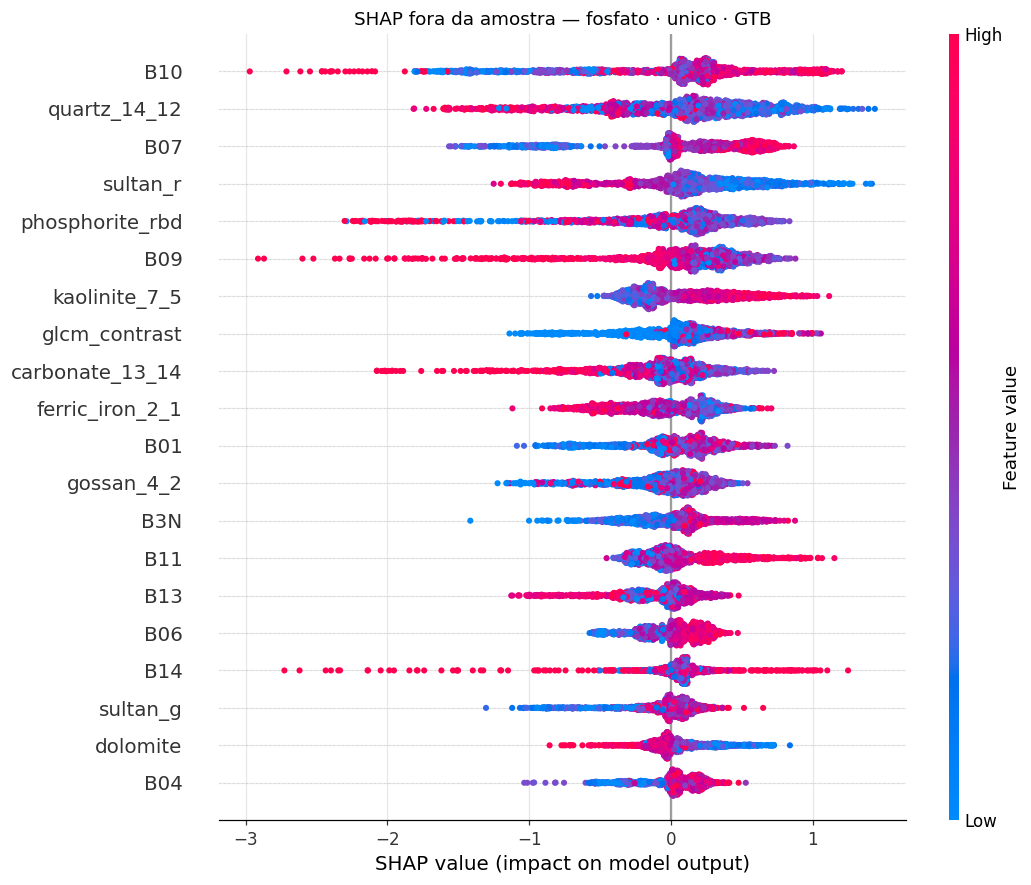

figura → c32_shap_dependencia_fosfato_unico_GTB.png
figura → c32_shap_beeswarm_fosfato_unico_RF.png


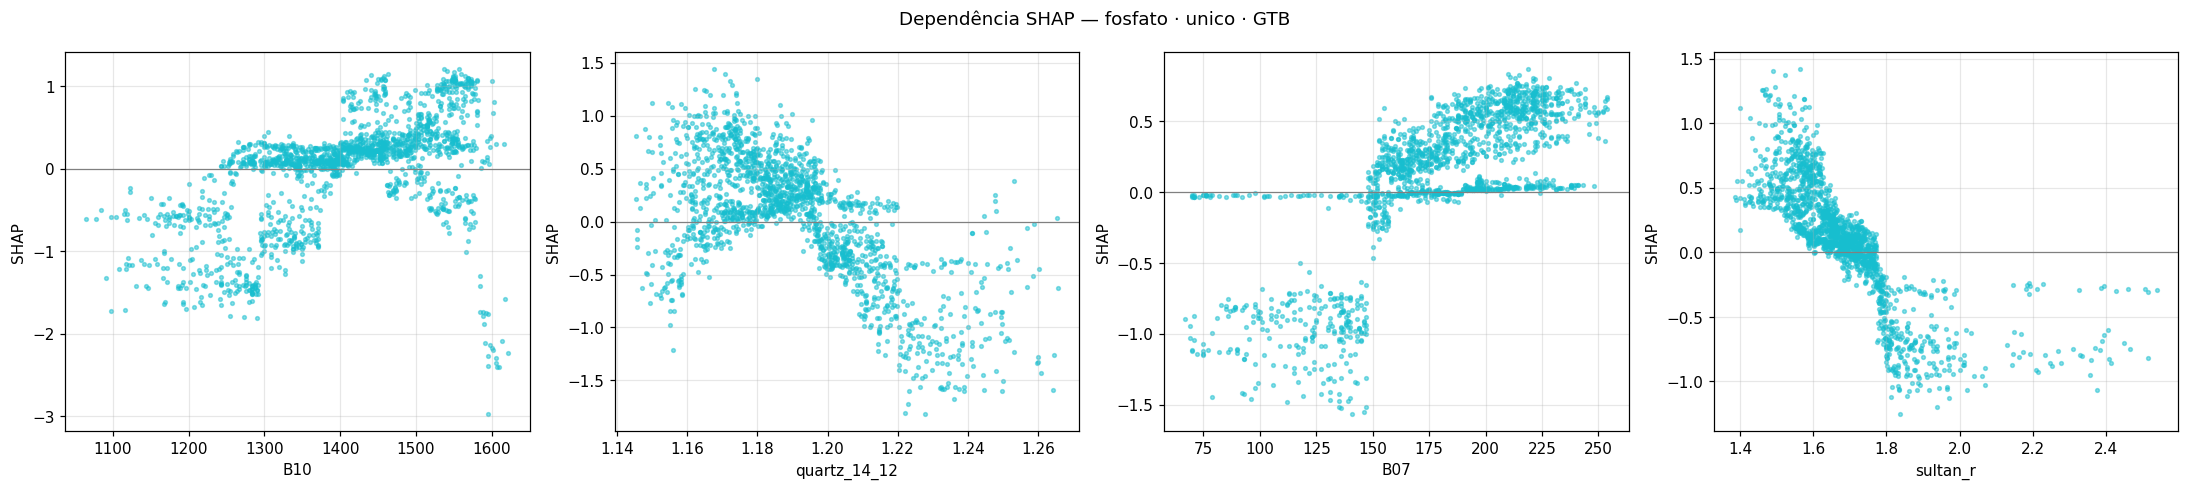

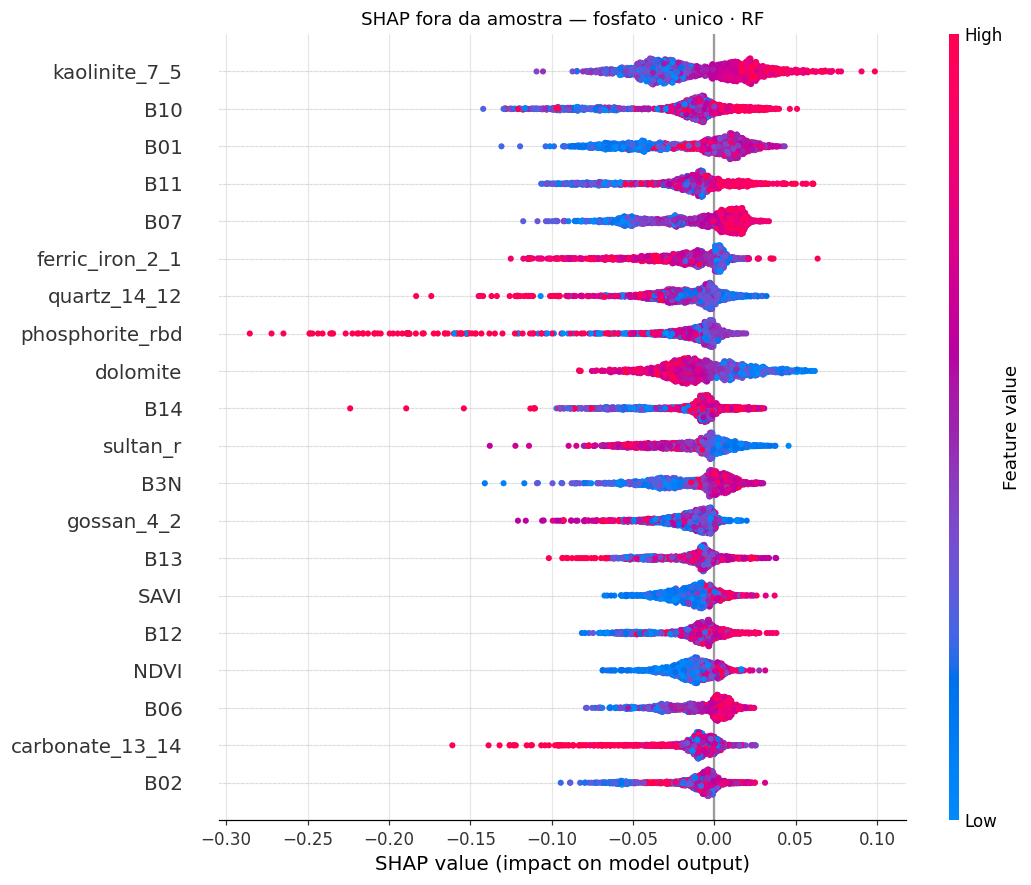

figura → c32_shap_dependencia_fosfato_unico_RF.png


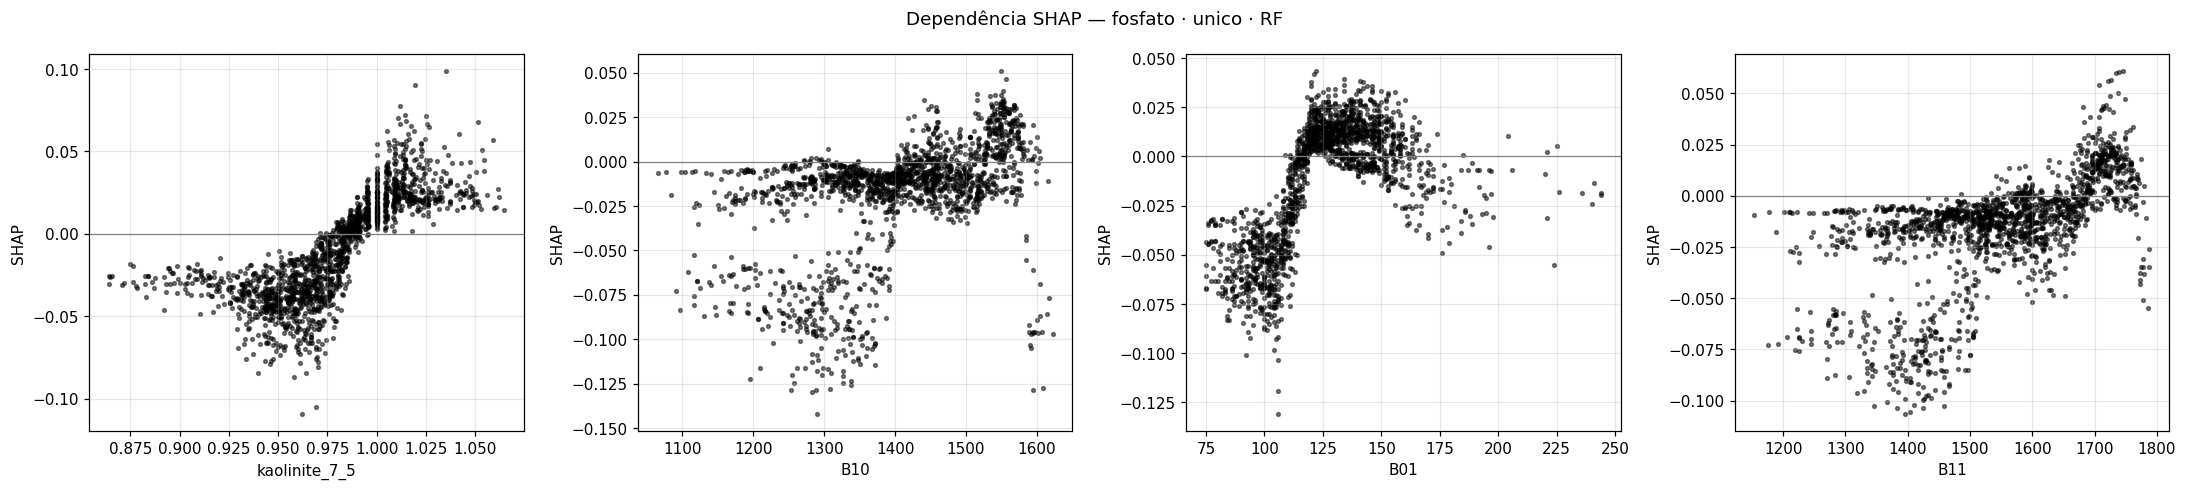

In [ ]:
# [32]
for nome_mod in SHAP_MODELOS:
    sv, X = SHAP_RES[(MOSAICO, ALVO, nome_mod)]
    plt.figure()
    shap.summary_plot(sv, X, max_display=20, show=False, plot_size=(10, 8))
    plt.title(f'SHAP fora da amostra — {ALVO} · {MOSAICO} · {nome_mod}')
    salvar(plt.gcf(), '32', f'shap_beeswarm_{ALVO}_{MOSAICO}_{nome_mod}')
    plt.show()

    top4 = np.array(FEATURES)[np.argsort(-np.abs(sv).mean(0))[:4]]
    fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
    for ax, feat in zip(axs, top4):
        j = FEATURES.index(feat)
        lo, hi = np.nanpercentile(X[feat], [1, 99])
        ok = (X[feat] >= lo) & (X[feat] <= hi)
        ax.scatter(X.loc[ok, feat], sv[ok.values, j], s=6, alpha=0.5, c=COR_MOD[nome_mod])
        ax.axhline(0, c='grey', lw=0.8)
        ax.set_xlabel(feat); ax.set_ylabel('SHAP')
    fig.suptitle(f'Dependência SHAP — {ALVO} · {MOSAICO} · {nome_mod}')
    fig.tight_layout()
    salvar(fig, '32', f'shap_dependencia_{ALVO}_{MOSAICO}_{nome_mod}')

figura → c33_shap_importancia_heatmap.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_avaliacao_maxent/c33_shap_importancia_heatmap.png')

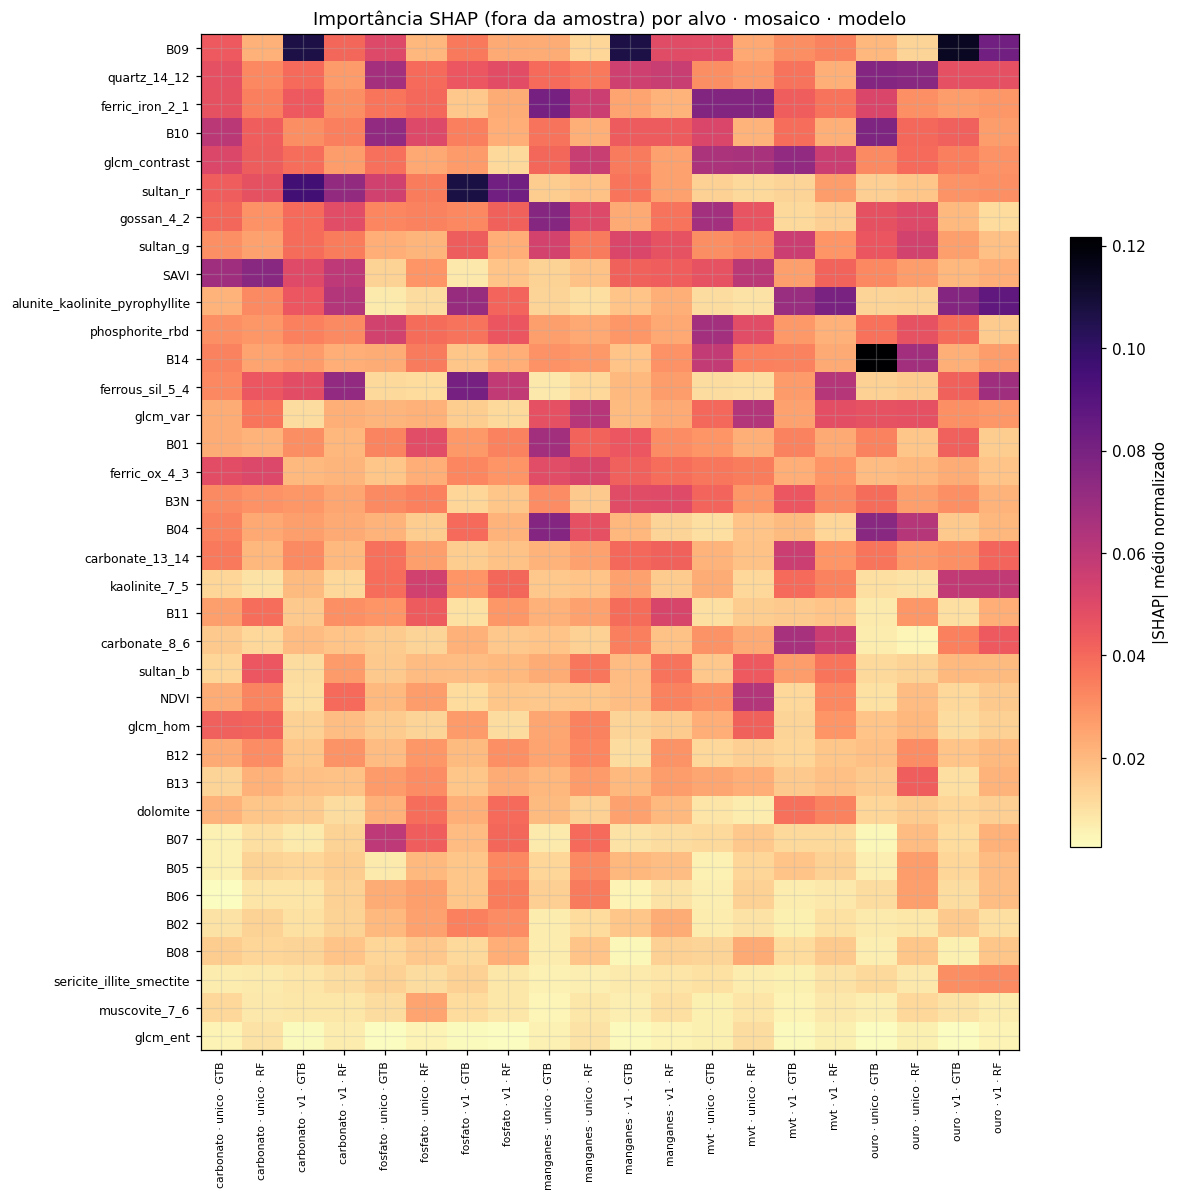

In [ ]:
# [33]
# importância normalizada por feature em cada alvo × mosaico × modelo
tab = IMP.pivot_table(index='feature', columns=['alvo', 'mosaico', 'modelo'], values='imp')
ordem_f = tab.mean(1).sort_values(ascending=False).index
tab = tab.loc[ordem_f]
fig, ax = plt.subplots(figsize=(max(12, 0.6 * tab.shape[1]), 12))
im = ax.imshow(tab.values, aspect='auto', cmap='magma_r')
ax.set_yticks(range(len(tab)), tab.index, fontsize=8)
ax.set_xticks(range(tab.shape[1]), [' · '.join(c) for c in tab.columns], rotation=90, fontsize=7)
fig.colorbar(im, shrink=0.6, label='|SHAP| médio normalizado')
ax.set_title('Importância SHAP (fora da amostra) por alvo · mosaico · modelo')
salvar(fig, '33', 'shap_importancia_heatmap')

figura → c34_shap_ranking_final.png
21 de 36 features selecionadas (|r| ≤ 0.9) → /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/ranking_features_shap_20261021.csv
FEATURES_DL = ['quartz_14_12', 'B10', 'ferric_iron_2_1', 'glcm_contrast', 'B09', 'sultan_g', 'phosphorite_rbd', 'gossan_4_2', 'sultan_r', 'ferric_ox_4_3', 'SAVI', 'B01', 'B3N', 'carbonate_13_14', 'kaolinite_7_5', 'carbonate_8_6', 'glcm_hom', 'dolomite', 'sericite_illite_smectite', 'muscovite_7_6', 'glcm_ent']

Por que quartz_14_12 é a mais importante (menor posto médio = 7.55):
  • em cada uma das 20 combinações alvo × mosaico × modelo as 36 variáveis
    são ordenadas pelo |SHAP| médio; posto 1 = a que mais muda a predição.
  • quartz_14_12 teve posto médio 7.55 — a melhor colocação típica de todas;
    a 2ª colocada, B10, ficou em 9.80.
  • ficou no top 10 em 14 das 20 combinações; melhor posto 1,
    pior 22 (desvio 5.6).
  • peso médio 0.045 = 1.6× o de uma variável qualquer (1/36 = 0

,feature,posto_medio,posto_dp,imp_media,vezes_top10,n_combinacoes,tipo,selecionada,descartada_por
0,quartz_14_12,7.55,5.633,0.045,14,20,índice,True,
1,B10,9.80,6.826,0.041,14,20,banda,True,
2,ferric_iron_2_1,10.00,7.284,0.041,11,20,índice,True,
3,glcm_contrast,10.30,7.699,0.041,13,20,textura,True,
4,B09,12.05,9.467,0.045,10,20,banda,True,
5,sultan_g,12.30,7.087,0.036,9,20,índice,True,
6,phosphorite_rbd,12.40,6.999,0.035,10,20,índice,True,
7,gossan_4_2,12.50,9.208,0.038,10,20,índice,True,
8,sultan_r,13.65,9.571,0.039,8,20,índice,True,
9,ferric_ox_4_3,14.00,7.327,0.031,7,20,índice,True,


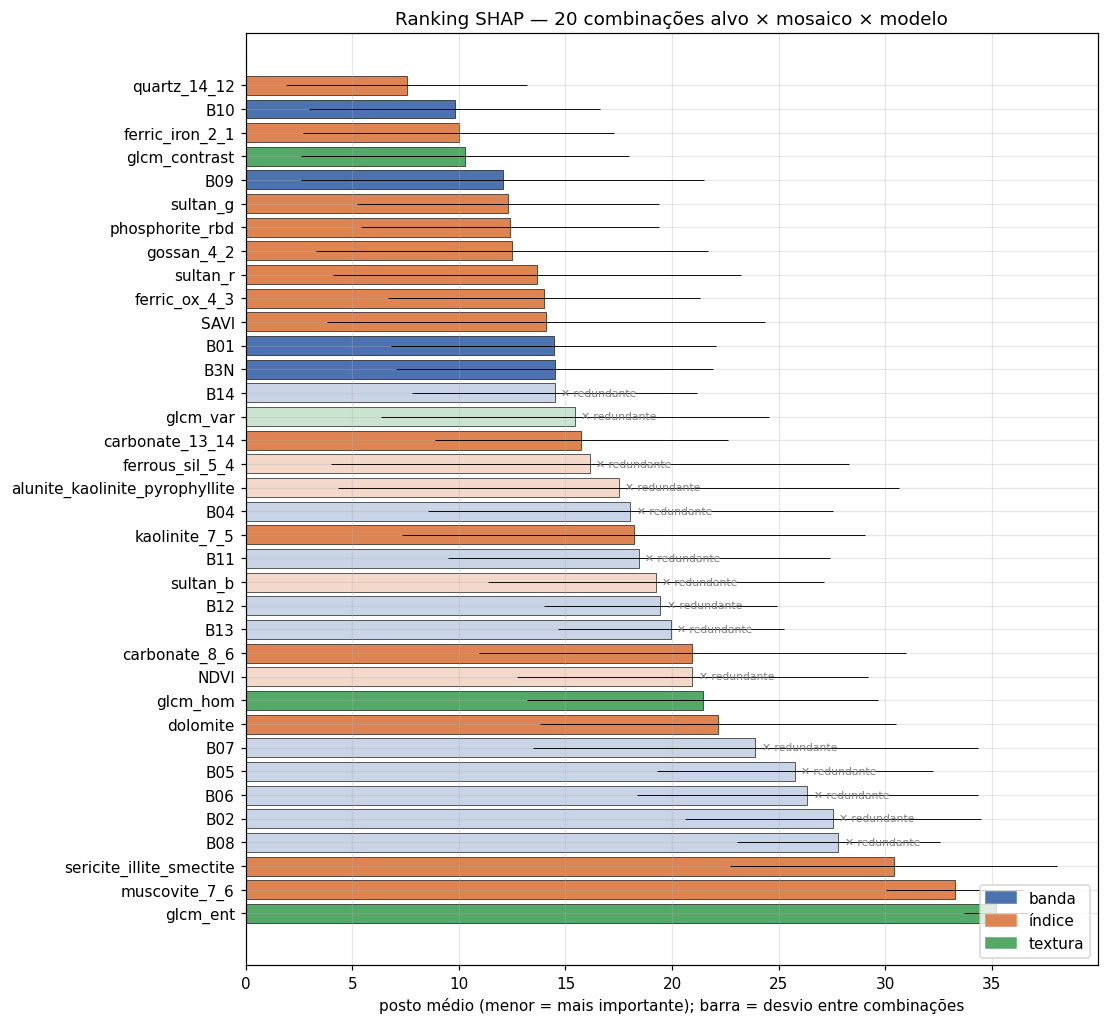

In [ ]:
# [34]
# ranking final: média dos postos em todas as combinações + seleção sem redundância
#
# Por que MENOR posto médio = MAIS importante:
#   em cada combinação (alvo × mosaico × modelo) as variáveis são ordenadas pelo
#   |SHAP| médio, do maior para o menor, e recebem um posto: 1 = a que mais mudou
#   a predição, 36 = a que menos mudou. O posto é uma colocação, como numa
#   corrida — 1º lugar é o melhor. A média dos postos nas 20 combinações resume
#   a colocação típica: quem fica em 7º em média esteve quase sempre entre as
#   primeiras; quem fica em 30º esteve quase sempre entre as últimas.
#   Usar o posto (e não o |SHAP| bruto) deixa as combinações comparáveis: o
#   tamanho do SHAP muda de um alvo/modelo para outro, a colocação não.
RANK = (IMP.groupby('feature')
           .agg(posto_medio=('posto', 'mean'), posto_dp=('posto', 'std'),
                imp_media=('imp', 'mean'), vezes_top10=('posto', lambda s: int((s <= 10).sum())))
           .sort_values('posto_medio').reset_index())
RANK['n_combinacoes'] = IMP.groupby(['mosaico', 'alvo', 'modelo']).ngroups
BANDAS_ASTER = ['B01', 'B02', 'B3N', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09',
                'B10', 'B11', 'B12', 'B13', 'B14']
RANK['tipo'] = np.where(RANK.feature.isin(BANDAS_ASTER), 'banda',
                        np.where(RANK.feature.str.startswith('glcm'), 'textura', 'índice'))

# correlação no fundo dos dois mosaicos juntos
fundo_tudo = pd.concat([d[d.classe == 0][FEATURES] for d in DADOS.values()])
corr_abs = fundo_tudo.corr().abs()
escolhidas, motivo = [], {}
for feat in RANK.feature:
    par = next((e for e in escolhidas if corr_abs.loc[feat, e] > R_MAX), None)
    if par is None:
        escolhidas.append(feat)
    else:
        motivo[feat] = f'|r| = {corr_abs.loc[feat, par]:.2f} com {par}'
RANK['selecionada'] = RANK.feature.isin(escolhidas)
RANK['descartada_por'] = RANK.feature.map(motivo).fillna('')
FEATURES_DL = escolhidas

fig, ax = plt.subplots(figsize=(10, 11))
r = RANK.iloc[::-1]
cor_tipo = {'banda': '#4c72b0', 'índice': '#dd8452', 'textura': '#55a868'}
# redundantes em cor clara
cor_barra = [cor_tipo[t] if sel else (*plt.matplotlib.colors.to_rgb(cor_tipo[t]), 0.3)
             for t, sel in zip(r.tipo, r.selecionada)]
ax.barh(r.feature, r.posto_medio, xerr=r.posto_dp, color=cor_barra, edgecolor='k', lw=0.4,
        error_kw={'lw': 0.6})
for k, (_, row) in enumerate(r.iterrows()):
    if not row.selecionada:
        ax.text(row.posto_medio + 0.3, k, '✕ redundante', va='center', fontsize=7, color='grey')
ax.set_xlabel('posto médio (menor = mais importante); barra = desvio entre combinações')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cor_tipo.values()], labels=list(cor_tipo),
          loc='lower right')
ax.set_title(f'Ranking SHAP — {RANK.n_combinacoes.iloc[0]} combinações alvo × mosaico × modelo')
salvar(fig, '34', 'shap_ranking_final')

arq_rank = MODELS / f'ranking_features_shap_{date.today():%Y%m%d}.csv'
RANK.to_csv(arq_rank, index=False)
print(f'{len(FEATURES_DL)} de {len(FEATURES)} features selecionadas (|r| ≤ {R_MAX}) → {arq_rank}')
print('FEATURES_DL =', FEATURES_DL)
# explicação da 1ª colocada com os números desta rodada
top = RANK.iloc[0]
im_top = IMP[IMP.feature == top.feature]
uniforme = 1 / len(FEATURES)
p_alvo = im_top.groupby('alvo').posto.mean().sort_values()
print(f"""
Por que {top.feature} é a mais importante (menor posto médio = {top.posto_medio:.2f}):
  • em cada uma das {top.n_combinacoes} combinações alvo × mosaico × modelo as {len(FEATURES)} variáveis
    são ordenadas pelo |SHAP| médio; posto 1 = a que mais muda a predição.
  • {top.feature} teve posto médio {top.posto_medio:.2f} — a melhor colocação típica de todas;
    a 2ª colocada, {RANK.feature.iloc[1]}, ficou em {RANK.posto_medio.iloc[1]:.2f}.
  • ficou no top 10 em {top.vezes_top10} das {top.n_combinacoes} combinações; melhor posto {im_top.posto.min():.0f},
    pior {im_top.posto.max():.0f} (desvio {top.posto_dp:.1f}).
  • peso médio {top.imp_media:.3f} = {top.imp_media / uniforme:.1f}× o de uma variável qualquer (1/{len(FEATURES)} = {uniforme:.3f}).
  • posto médio por alvo: {', '.join(f'{a} {v:.1f}' for a, v in p_alvo.items())}.
  Leitura: menor posto médio = esteve, na média, mais perto do 1º lugar. Não quer dizer
  que domina — compare o peso ({top.imp_media / uniforme:.1f}× o uniforme) e o desvio do posto.
""")
RANK.round(3)

In [ ]:
# [34a]
# Lista das variáveis por importância, com o porquê de cada posição.
# Junta: o que a variável mede, direção do efeito (SHAP), em que alvos ela pesa,
# estabilidade entre combinações, diferença entre mosaicos e modelos, redundância.
from scipy.stats import spearmanr

SIGNIFICADO = {
    'B01': 'verde (0,56 µm) — brilho do solo/rocha', 'B02': 'vermelho (0,66 µm) — Fe³⁺, solo exposto',
    'B3N': 'infravermelho próximo (0,81 µm) — vegetação, brilho', 'B04': 'SWIR 1,65 µm — brilho geral, umidade',
    'B05': 'SWIR 2,17 µm — Al-OH (caulinita)', 'B06': 'SWIR 2,21 µm — Al-OH (ilita, sericita)',
    'B07': 'SWIR 2,26 µm — Al-OH / Fe-OH', 'B08': 'SWIR 2,33 µm — carbonato, Mg-OH',
    'B09': 'SWIR 2,40 µm — ombro do carbonato', 'B10': 'TIR 8,3 µm — sílica (Reststrahlen), temperatura',
    'B11': 'TIR 8,6 µm — sílica', 'B12': 'TIR 9,1 µm — sílica, apatita', 'B13': 'TIR 10,7 µm — temperatura, carbonato',
    'B14': 'TIR 11,3 µm — temperatura, carbonato',
    'NDVI': 'vegetação verde', 'SAVI': 'vegetação com correção de solo',
    'ferric_iron_2_1': 'Fe³⁺ (hematita/goethita) B02/B01', 'ferric_ox_4_3': 'óxidos férricos B04/B3N',
    'gossan_4_2': 'gossan/alteração oxidada B04/B02', 'ferrous_sil_5_4': 'silicatos ferrosos B05/B04',
    'sericite_illite_smectite': 'Al-OH: sericita/ilita/esmectita', 'alunite_kaolinite_pyrophyllite': 'Al-OH: alunita/caulinita/pirofilita',
    'muscovite_7_6': 'muscovita B07/B06', 'kaolinite_7_5': 'caulinita B07/B05', 'dolomite': 'dolomita (B06+B08)/B07',
    'carbonate_8_6': 'carbonato SWIR B08/B06', 'carbonate_13_14': 'carbonato TIR B13/B14', 'quartz_14_12': 'quartzo TIR B14/B12',
    'phosphorite_rbd': 'apatita/fosforito — feição de emissividade em 9 µm', 'sultan_r': 'Sultan R B04/B07 (alteração)',
    'sultan_g': 'Sultan G B04/B01 (máficos/ferro)', 'sultan_b': 'Sultan B (B02/B3N)·(B04/B3N)',
    'glcm_contrast': 'textura B3N: contraste (bordas, relevo, lavouras)', 'glcm_var': 'textura B3N: variância',
    'glcm_ent': 'textura B3N: entropia (desordem)', 'glcm_hom': 'textura B3N: homogeneidade',
}

# direção do efeito: correlação de Spearman entre valor da feature e SHAP, por combinação
dir_linhas = []
for (mos, a, mod), (sv, X) in SHAP_RES.items():
    for j, feat in enumerate(FEATURES):
        rho = spearmanr(X[feat].values, sv[:, j]).statistic
        dir_linhas.append({'mosaico': mos, 'alvo': a, 'modelo': mod, 'feature': feat, 'rho': rho})
DIR = pd.DataFrame(dir_linhas)

def direcao(feat):
    d = DIR[DIR.feature == feat].rho.dropna()
    pos = (d > 0.2).sum(); neg = (d < -0.2).sum(); n = len(d)
    if pos >= 0.7 * n: return f'valor ALTO favorece ({pos}/{n})'
    if neg >= 0.7 * n: return f'valor BAIXO favorece ({neg}/{n})'
    return f'direção muda conforme o alvo ({pos}↑ {neg}↓ de {n})'

def direcao_alvo(feat, alvo):
    d = DIR[(DIR.feature == feat) & (DIR.alvo == alvo)].rho.mean()
    return '↑' if d > 0.2 else '↓' if d < -0.2 else '~'

uniforme = 1 / len(FEATURES)
linhas = []
for _, r in RANK.iterrows():
    f_ = r.feature
    im = IMP[IMP.feature == f_]
    p_alvo = im.groupby('alvo').posto.mean()
    fortes = [f'{a} ({direcao_alvo(f_, a)})' for a in p_alvo[p_alvo <= 10].sort_values().index]
    p_mos = im.groupby('mosaico').posto.mean()
    p_mod = im.groupby('modelo').posto.mean()
    estab = ('estável' if r.posto_dp < 6 else 'varia bastante' if r.posto_dp < 9 else 'muito instável')
    partes = [
        f'{SIGNIFICADO.get(f_, "")}.',
        f'Peso médio {r.imp_media / uniforme:.1f}× o de uma variável qualquer; top 10 em {r.vezes_top10}/{r.n_combinacoes} combinações ({estab}, dp do posto {r.posto_dp:.1f}).',
        f'{direcao(f_)}.',
        f'Pesa mais para: {", ".join(fortes)}.' if fortes else 'Não fica no top 10 de nenhum alvo em média.',
    ]
    if abs(p_mos.get('unico', np.nan) - p_mos.get('v1', np.nan)) >= 6:
        partes.append(f'Depende do mosaico: posto {p_mos["unico"]:.0f} no único × {p_mos["v1"]:.0f} no v1.')
    if abs(p_mod.get('RF', np.nan) - p_mod.get('GTB', np.nan)) >= 6:
        partes.append(f'RF e GTB discordam: posto {p_mod["RF"]:.0f} (RF) × {p_mod["GTB"]:.0f} (GTB).')
    partes.append('→ entra na FEATURES_DL.' if r.selecionada else f'→ fora: redundante ({r.descartada_por}).')
    linhas.append({'posto': len(linhas) + 1, 'feature': f_, 'tipo': r.tipo, 'posto_medio': r.posto_medio,
                   'selecionada': r.selecionada, 'porque': ' '.join(partes)})
EXPLICA = pd.DataFrame(linhas)

for _, r in EXPLICA.iterrows():
    marca = '✔' if r.selecionada else '✕'
    print(f'{r.posto:2d}. {marca} {r.feature}  [{r.tipo}, posto médio {r.posto_medio:.1f}]\n    {r.porque}\n')

arq_exp = MODELS / f'ranking_features_shap_explicado_{date.today():%Y%m%d}.csv'
EXPLICA.to_csv(arq_exp, index=False)
print(f'→ {arq_exp}')

 1. ✔ quartz_14_12  [índice, posto médio 7.5]
    quartzo TIR B14/B12. Peso médio 1.6× o de uma variável qualquer; top 10 em 14/20 combinações (estável, dp do posto 5.6). direção muda conforme o alvo (10↑ 10↓ de 20). Pesa mais para: ouro (↑), fosfato (↓), manganes (↑). → entra na FEATURES_DL.

 2. ✔ B10  [banda, posto médio 9.8]
    TIR 8,3 µm — sílica (Reststrahlen), temperatura. Peso médio 1.5× o de uma variável qualquer; top 10 em 14/20 combinações (varia bastante, dp do posto 6.8). direção muda conforme o alvo (9↑ 7↓ de 20). Pesa mais para: carbonato (↑), ouro (~), fosfato (↑). RF e GTB discordam: posto 13 (RF) × 6 (GTB). → entra na FEATURES_DL.

 3. ✔ ferric_iron_2_1  [índice, posto médio 10.0]
    Fe³⁺ (hematita/goethita) B02/B01. Peso médio 1.5× o de uma variável qualquer; top 10 em 11/20 combinações (varia bastante, dp do posto 7.3). direção muda conforme o alvo (12↑ 3↓ de 20). Pesa mais para: mvt (↑), carbonato (↑). Depende do mosaico: posto 6 no único × 14 no v1. → entra na F

`[34b]`

### Como ler o gráfico da célula 34

- **Uma barra por variável**, ordenadas de cima (mais importante) para baixo.
- **Comprimento da barra = posto médio.** Em cada uma das 20 combinações
  (5 alvos × 2 mosaicos × 2 modelos) as 36 variáveis são ordenadas pelo |SHAP|
  médio: posto 1 = a que mais pesou, 36 = a que menos pesou. A barra é a média
  desses 20 postos — **barra curta = mais importante**.
- **Traço preto (barra de erro) = desvio-padrão do posto.** Traço curto = a
  variável fica sempre mais ou menos na mesma posição (importância geral);
  traço longo = sobe muito em alguns alvos/mosaicos e cai em outros
  (importância específica). Ex.: posto médio 12 ± 9 quer dizer que ela já foi
  3ª e já foi 21ª.
- **Cor = tipo:** azul banda, laranja índice, verde textura.
- **Cor clara + "✕ redundante"** = ficou fora da `FEATURES_DL` porque tem
  |r| > `R_MAX` com outra variável **mais bem colocada** (motivo na coluna
  `descartada_por`). Não quer dizer que não presta — a informação dela já
  entra pela outra. Ex.: B11–B14 saem por causa da B10 (as bandas TIR variam
  juntas, quase só pela temperatura); B05–B08 saem por causa da B09.

**Cuidados na leitura**
- O posto é relativo. Olhe também `imp_media` na tabela (ou o "peso médio ×"
  na lista da 34a): 1× = o que cada variável teria se todas pesassem igual
  (1/36). Se as primeiras ficam só em 1,5–2×, **nenhuma variável domina** — o
  modelo usa um pouco de muitas, e a ordem entre postos vizinhos (7 × 10, por
  exemplo) é ruído.
- Desvios-padrão grandes em quase todas = os alvos usam variáveis diferentes;
  um ranking único é um compromisso. Para um alvo só, use a coluna "pesa mais
  para" da 34a ou o heatmap da 33.
- A importância vem de SHAP **fora da amostra**: variável alta aqui ajuda em
  células que o modelo não viu, não só onde estão os pontos de treino.

`[35]`

### Como usar o ranking no deep learning

- **Entrada:** `FEATURES_DL` (ranking sem redundância). Para um teste rápido de
  quantas entram, treine o GTB com as *k* primeiras (k = 5, 10, 15, 20…) na
  mesma validação por célula e pare quando a AUC parar de subir.
- **Estáveis × específicas:** `posto_dp` baixo = a feature é boa em todos os
  alvos e mosaicos (candidata a entrada comum de uma rede multitarefa, uma
  saída por alvo). `posto_dp` alto = útil só para alguns alvos.
- **Mosaico:** se o ranking mudar muito entre `unico` e `v1` (heatmap da
  célula 33), a feature depende da radiometria do mosaico — sinal de que a
  rede vai precisar de normalização por cena ou de aumento de dados.
- **Validação:** a mesma da seção 3 (célula de fora). Com ~1.100 pontos,
  uma rede só vale se passar o GTB/RF nessa validação.